In [2]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 5050
VRAM: 7.93 GB


In [3]:
%pip install -U transformers datasets peft trl accelerate bitsandbytes sentencepiece safetensors

Note: you may need to restart the kernel to use updated packages.


In [4]:
import torch
import transformers
import datasets
import peft
import accelerate

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("PEFT:", peft.__version__)
print("Accelerate:", accelerate.__version__)

W1010 23:37:17.839000 18876 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


PyTorch: 2.11.0+cu128
CUDA available: True
Transformers: 5.19.0
Datasets: 5.1.0
PEFT: 0.21.2
Accelerate: 1.15.0


In [5]:
%pip install --force-reinstall --no-cache-dir pyarrow

   ---------------------------------------- 0.0/29.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/29.2 MB ? eta -:--:--
   -- ------------------------------------- 1.6/29.2 MB 5.7 MB/s eta 0:00:05
   --- ------------------------------------ 2.6/29.2 MB 5.9 MB/s eta 0:00:05
   ----- ---------------------------------- 3.9/29.2 MB 6.1 MB/s eta 0:00:05
   ------- -------------------------------- 5.2/29.2 MB 6.1 MB/s eta 0:00:04
   -------- ------------------------------- 6.6/29.2 MB 6.1 MB/s eta 0:00:04
   ---------- ----------------------------- 7.9/29.2 MB 6.1 MB/s eta 0:00:04
   ------------ --------------------------- 9.2/29.2 MB 6.1 MB/s eta 0:00:04
   -------------- ------------------------- 10.5/29.2 MB 6.1 MB/s eta 0:00:04
   ---------------- ----------------------- 11.8/29.2 MB 6.2 MB/s eta 0:00:03
   ----------------- ---------------------- 13.1/29.2 MB 6.1 MB/s eta 0:00:03
   ------------------- -------------------- 14.4/29.2 MB 6.2 MB/s eta 0:00:03
   ------

  You can safely remove it manually.
  You can safely remove it manually.


In [6]:
import sys
import torch
import pyarrow
import datasets
import transformers
import peft
import accelerate

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("PyArrow:", pyarrow.__version__)
print("Datasets:", datasets.__version__)
print("Transformers:", transformers.__version__)
print("PEFT:", peft.__version__)
print("Accelerate:", accelerate.__version__)

print("\nAll imports successful!")

Python: C:\Users\Admin\anaconda3\python.exe
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 5050
PyArrow: 26.0.0
Datasets: 5.1.0
Transformers: 5.19.0
PEFT: 0.21.2
Accelerate: 1.15.0

All imports successful!


In [7]:
import torch
print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

CUDA: True
GPU: NVIDIA GeForce RTX 5050


In [8]:
import os, sys, platform, subprocess, importlib.metadata as metadata
print("Python executable:", sys.executable)
print("Python:", platform.python_version())
print("Platform:", platform.platform())
try:
    print(subprocess.run(["nvidia-smi"], capture_output=True, text=True, check=True).stdout)
except Exception as e:
    print("nvidia-smi could not run:", repr(e))
try:
    import torch
    print("PyTorch:", torch.__version__)
    print("Torch CUDA build:", torch.version.cuda)
    print("CUDA available:", torch.cuda.is_available())
    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
        p = torch.cuda.get_device_properties(0)
        print(f"VRAM total: {p.total_memory / 1024**3:.2f} GB")
        free, total = torch.cuda.mem_get_info()
        print(f"VRAM free now: {free / 1024**3:.2f} GB / {total / 1024**3:.2f} GB")
        print("BF16 supported:", torch.cuda.is_bf16_supported())
except ImportError:
    print("PyTorch is not installed in this kernel.")


Python executable: C:\Users\Admin\anaconda3\python.exe
Python: 3.14.6
Platform: Windows-11-10.0.26200-SP0
Sat Oct 10 23:37:59 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 616.92                 KMD Version: 616.92        CUDA UMD Version: 13.4     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5050      WDDM  |   00000000:29:00.0  On |                  N/A |
| 34%   38C    P8             12W /  130W |     821MiB /   8151MiB |      0%      Default |
|                                 

In [9]:
# Uncomment and run ONLY if required packages are missing or incompatible.
# %pip install "transformers==4.51.3" "trl==0.15.2" "peft==0.15.2" "accelerate==1.2.1" "bitsandbytes>=0.46.1" "datasets==3.6.0" "scikit-learn" "pandas" "numpy" "tqdm" "matplotlib"


In [10]:
import gc, json, time, random, shutil, inspect, re, math
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import torch
import datasets, transformers, peft, trl, accelerate, bitsandbytes as bnb
from datasets import load_dataset, Dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig, set_seed
from peft import LoraConfig, prepare_model_for_kbit_training, get_peft_model
from trl import SFTTrainer, SFTConfig
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix
from tqdm.auto import tqdm

SEED = 42
set_seed(SEED); random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

DATASET_NAME = "nahid-hub/BLUGE-bengali-news-classification"
BASE_MODEL = "Qwen/Qwen2.5-3B-Instruct"
OUTPUT_ROOT = Path.cwd() / "bengali_classification_experiments"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
FRACTIONS = [1.00]  # This notebook supports only the 100% experiment
LABEL_NAMES = ["Business", "Technology", "Crime", "Entertainment", "International Affairs", "Sports", "Lifestyle"]
MAX_LENGTH = 512

print("PyTorch:", torch.__version__, "| CUDA build:", torch.version.cuda)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("PEFT:", peft.__version__)
print("TRL:", trl.__version__)
print("Accelerate:", accelerate.__version__)
print("BitsAndBytes:", getattr(bnb, "__version__", "unknown"))
print("Output root:", OUTPUT_ROOT.resolve())
if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is not available to this Jupyter kernel. Fix the NVIDIA driver/PyTorch environment before training.")


PyTorch: 2.11.0+cu128 | CUDA build: 12.8
Transformers: 5.19.0
Datasets: 5.1.0
PEFT: 0.21.2
TRL: 1.15.0
Accelerate: 1.15.0
BitsAndBytes: 0.50.2
Output root: C:\Users\Admin\bengali_classification_experiments


In [11]:
dataset = load_dataset(DATASET_NAME)
print(dataset)
print("Splits:", {k: len(v) for k, v in dataset.items()})
for split_name, split in dataset.items():
    print(f"\n{split_name} columns:", split.column_names)
    print("Features:", split.features)
    print("Example:", split[0])

required_splits = {"train", "validation", "test"}
if not required_splits.issubset(dataset.keys()):
    raise ValueError(f"Expected splits {required_splits}, found {list(dataset.keys())}")
train_raw, validation_raw, test_raw = dataset["train"], dataset["validation"], dataset["test"]
for name, split in [("train", train_raw), ("validation", validation_raw), ("test", test_raw)]:
    if not {"text", "label"}.issubset(split.column_names):
        raise ValueError(f"{name} must contain 'text' and 'label'. Found {split.column_names}")
    labels = set(int(x) for x in split["label"] if x is not None)
    print(f"{name}: {len(split):,} rows; labels={sorted(labels)}")
    if labels != set(range(7)):
        raise ValueError(f"Unexpected labels in {name}: {labels}")
print("Expected reference sizes: train=49,840; validation=6,230; test=6,230. Investigate any mismatch rather than silently changing the dataset.")


DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 49840
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 6230
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 6230
    })
})
Splits: {'train': 49840, 'validation': 6230, 'test': 6230}

train columns: ['text', 'label']
Features: {'text': Value('string'), 'label': Value('int64')}
Example: {'text': 'পবিত্র ঈদুল আজহায় কোরবানি দেওয়া পশুর মাংস অনেক দিন পর্যন্ত সংরক্ষণ করা হয় ফ্রিজে রেখে। যার ঘরে ফ্রিজ আছে, তিনি আরেকটি ডিপ ফ্রিজের চাহিদা অনুভব করেন। আর যার নেই তিনি কোরবানির আগে ফ্রিজের দোকানে ছোটেন। এসব কারণেই গত এক মাসে ফ্রিজের চাহিদা বেড়েছে, বেড়েছে বেচাকেনাও।ফ্রিজের আমদানিকারক, দেশীয় প্রস্তুতকারক এবং বিক্রেতাদের সঙ্গে কথা বলে জানা গেছে, এবার ফ্রিজের বিক্রি ভালো। বরাবরের মতোই বেশি বিক্রি হচ্ছে ডিপ ফ্রিজ।সংশ্লিষ্ট ব্যবসায়ীরা বলছেন, সারা বছর দেশে প্রায় ১১ লাখ ফ্রিজ বিক্রি হয়। এর প্রায় ৩০ শতাংশই বিক্রি হয় কোরবানির ঈদের আগে। অর্থা

In [12]:
def clean_split(split, split_name):
    df = split.to_pandas()[["text", "label"]].copy()
    before = len(df)
    df["text"] = df["text"].astype("string").str.strip()
    df["label"] = pd.to_numeric(df["label"], errors="coerce")
    df = df[df["text"].notna() & (df["text"] != "") & df["label"].notna()].copy()
    df["label"] = df["label"].astype(int)
    df = df[df["label"].isin(range(7))].copy()
    # Preserve source rows and ordering; report duplicate counts rather than silently removing them.
    duplicate_texts = int(df["text"].duplicated().sum())
    print(f"{split_name}: before={before:,}, after validity filter={len(df):,}, duplicate text rows={duplicate_texts:,}")
    return Dataset.from_pandas(df.reset_index(drop=True), preserve_index=False)

train_clean = clean_split(train_raw, "train")
validation_clean = clean_split(validation_raw, "validation")
test_clean = clean_split(test_raw, "test")
if not len(train_clean) or not len(validation_clean) or not len(test_clean):
    raise ValueError("A split became empty after validation.")


train: before=49,840, after validity filter=49,840, duplicate text rows=164
validation: before=6,230, after validity filter=6,230, duplicate text rows=2
test: before=6,230, after validity filter=6,230, duplicate text rows=6


In [13]:
# Use every valid training example for the only experiment in this notebook.
train_df = train_clean.to_pandas().reset_index(drop=True)
RUN_FRACTION = 1.00
fraction_metadata = {
    1.00: Dataset.from_pandas(train_df, preserve_index=False)
}

fraction_dir = OUTPUT_ROOT / "100_percent"
fraction_dir.mkdir(parents=True, exist_ok=True)

# Save source row indices after the validity filter so the exact training set is auditable.
source_indices = list(range(len(train_df)))
with open(fraction_dir / "selected_source_indices.json", "w", encoding="utf-8") as f:
    json.dump(source_indices, f)

fraction_info = {
    "100_percent": {
        "count": len(fraction_metadata[1.00]),
        "source_indices_file": "100_percent/selected_source_indices.json"
    }
}
with open(OUTPUT_ROOT / "data_fraction_metadata.json", "w", encoding="utf-8") as f:
    json.dump(fraction_info, f, indent=2)

print("Experiment: 100% training data")
print("Valid training examples:", f"{len(fraction_metadata[1.00]):,}")
print("Class counts:", fraction_metadata[1.00].to_pandas()["label"].value_counts().sort_index().to_dict())
print("Validation examples (fixed):", f"{len(validation_clean):,}")
print("Test examples (reserved):", f"{len(test_clean):,}")


Experiment: 100% training data
Valid training examples: 49,840
Class counts: {0: 7120, 1: 7120, 2: 7120, 3: 7120, 4: 7120, 5: 7120, 6: 7120}
Validation examples (fixed): 6,230
Test examples (reserved): 6,230


In [14]:
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

SYSTEM_PROMPT = (
    "You are a Bengali news classification assistant. "
    "Classify the given Bengali news article into exactly one "
    "of the following categories: Business, Technology, Crime, "
    "Entertainment, International Affairs, Sports, Lifestyle. "
    "Return only the category name and nothing else."
)
def build_user_prompt(text):
    return "নিচের বাংলা সংবাদটর সঠিক category নির্ধারণ করো।\n\nসংবাদ:\n" + str(text) + "\n\nশুধু একটি category name লিখবে।"

def format_example(example):
    label_id = int(example["label"])
    if label_id not in range(7):
        raise ValueError(f"Invalid label: {label_id}")
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": build_user_prompt(example["text"])}
    ]
    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    return {"prompt": prompt, "completion": LABEL_NAMES[label_id]}

validation_dataset = validation_clean.map(format_example, remove_columns=validation_clean.column_names, desc="Formatting validation")
print("Tokenizer vocab:", len(tokenizer))
print("Validation examples:", len(validation_dataset))
print("Formatted sample:", validation_dataset[0])


Formatting validation:   0%|          | 0/6230 [00:00<?, ? examples/s]

Tokenizer vocab: 151665
Validation examples: 6230
Formatted sample: {'prompt': '<|im_start|>system\nYou are a Bengali news classification assistant. Classify the given Bengali news article into exactly one of the following categories: Business, Technology, Crime, Entertainment, International Affairs, Sports, Lifestyle. Return only the category name and nothing else.<|im_end|>\n<|im_start|>user\nনিচের বাংলা সংবাদটির সঠিক category নির্ধারণ করো।\n\nসংবাদ:\nবিদেশি বিনিয়োগকারীদের সংগঠন ফরেন চেম্বার অব কমার্স অ্যান্ড ইন্ডাস্ট্রি (এফআইসিসিআই) বলেছে, দেশের বর্তমান অর্থনৈতিক পরিস্থিতিতে ২০১৩-১৪ অর্থবছরের দুই লাখ ২২ হাজার ৪৯১ কোটি টাকার বাজেট বাস্তবায়ন করা হবে চ্যালেঞ্জের।এফআইসিসিআই গতকাল শুক্রবার বাজেট প্রতিক্রিয়ায় এ কথা বলেছে। সংগঠনটি মনে করে, বাজেটের লক্ষ্যগুলো অর্জনে জোর তদারকির প্রয়োজন রয়েছে।এফআইসিসিআই বিশেষ করে পরিবহন ও যোগাযোগ খাতে বরাদ্দ প্রদানসহ বাজেটের কিছু পদক্ষেপের প্রশংসা করেছে। তবে মানবসম্পদের উন্নয়নে অপরিহার্য বিবেচিত শিক্ষা, তথ্যপ্রযুক্তি ও স্বাস্থ্য খাতে তুলনামূলক কম বরাদ্দে উদ্

In [15]:
def experiment_paths(fraction):
    name = f"{int(fraction*100)}_percent"
    root = OUTPUT_ROOT / name
    return {
        "root": root,
        "checkpoints": root / "checkpoints",
        "final_adapter": root / "final_adapter",
        "predictions": root / "predictions.csv",
        "metrics": root / "metrics.json",
        "metadata": root / "training_info.json",
        "logs": root / "training_log.json"
    }

def write_json(path, obj):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False, default=str)

def make_fresh_qlora_model():
    if not torch.cuda.is_available(): raise RuntimeError("CUDA unavailable")
    torch.cuda.empty_cache(); gc.collect()
    compute_dtype = torch.float16  # matches the previous notebook's fp16 configuration
    quant_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=compute_dtype,
    )
    base = AutoModelForCausalLM.from_pretrained(
        BASE_MODEL,
        quantization_config=quant_config,
        device_map="auto",
        torch_dtype=compute_dtype,
    )
    base.config.use_cache = False
    base = prepare_model_for_kbit_training(base, use_gradient_checkpointing=True)
    lora_config = LoraConfig(
        r=8, lora_alpha=16, lora_dropout=0.05, bias="none",
        task_type="CAUSAL_LM", target_modules=["q_proj", "v_proj"]
    )
    model = get_peft_model(base, lora_config)
    model.print_trainable_parameters()
    if not getattr(model, "is_loaded_in_4bit", False):
        # Depending on PEFT wrapper, check the underlying base model as well.
        inner = getattr(model, "base_model", None)
        inner_model = getattr(inner, "model", None)
        if not getattr(inner_model, "is_loaded_in_4bit", False):
            print("Warning: verify 4-bit loading in the model printout before proceeding.")
    return model

print("Checkpoint root will be local:", OUTPUT_ROOT.resolve())


Checkpoint root will be local: C:\Users\Admin\bengali_classification_experiments


In [16]:
def build_trainer(model, train_dataset, validation_dataset, output_dir):
    sft_params = inspect.signature(SFTConfig.__init__).parameters
    trainer_params = inspect.signature(SFTTrainer.__init__).parameters
    values = {
        "output_dir": str(output_dir),
        "num_train_epochs": 3,
        "learning_rate": 2e-4,
        "per_device_train_batch_size": 1,
        "per_device_eval_batch_size": 1,
        "gradient_accumulation_steps": 8,
        "warmup_ratio": 0.03,
        "lr_scheduler_type": "cosine",
        "fp16": True,
        "bf16": False,
        "gradient_checkpointing": True,
        "gradient_checkpointing_kwargs": {"use_reentrant": False},
        "optim": "paged_adamw_8bit",
        "packing": False,
        "eval_steps": 500,
        "save_steps": 500,
        "save_total_limit": 2,
        "load_best_model_at_end": True,
        "metric_for_best_model": "eval_loss",
        "greater_is_better": False,
        "logging_steps": 25,
        "report_to": "none",
        "seed": SEED,
        "data_seed": SEED,
    }
    if "max_seq_length" in sft_params: values["max_seq_length"] = MAX_LENGTH
    elif "max_length" in sft_params: values["max_length"] = MAX_LENGTH
    else: raise RuntimeError("Installed SFTConfig has no supported max sequence length argument.")
    if "completion_only_loss" in sft_params: values["completion_only_loss"] = True
    if "eval_strategy" in sft_params: values["eval_strategy"] = "steps"
    elif "evaluation_strategy" in sft_params: values["evaluation_strategy"] = "steps"
    else: raise RuntimeError("Installed SFTConfig has no supported evaluation strategy argument.")
    if "save_strategy" in sft_params: values["save_strategy"] = "steps"
    # Only pass constructor arguments supported by this installed version.
    values = {k:v for k,v in values.items() if k in sft_params}
    args = SFTConfig(**values)
    kwargs = {"model": model, "args": args, "train_dataset": train_dataset, "eval_dataset": validation_dataset}
    if "processing_class" in trainer_params: kwargs["processing_class"] = tokenizer
    elif "tokenizer" in trainer_params: kwargs["tokenizer"] = tokenizer
    # Prompt-completion datasets use completion-only loss in TRL versions that support it.
    if "dataset_text_field" in trainer_params and "formatting_func" not in trainer_params:
        pass
    trainer = SFTTrainer(**kwargs)
    print("TRL:", trl.__version__, "| sequence length:", MAX_LENGTH)
    print("Trainer args:", {k: getattr(args, k, None) for k in ["num_train_epochs", "learning_rate", "warmup_ratio", "warmup_steps", "save_steps", "eval_steps"]})
    return trainer


In [ ]:
RUN_FRACTION = 1.00  # This notebook runs only the 100% experiment
if RUN_FRACTION != 1.00: raise ValueError("This notebook is restricted to the 100% experiment.")
paths = experiment_paths(RUN_FRACTION)
for p in paths.values():
    if isinstance(p, Path) and p.suffix == "": p.mkdir(parents=True, exist_ok=True)

train_dataset = fraction_metadata[RUN_FRACTION].map(
    format_example,
    remove_columns=fraction_metadata[RUN_FRACTION].column_names,
    desc=f"Formatting {int(RUN_FRACTION*100)}% training data"
)
print("Experiment:", f"{int(RUN_FRACTION*100)}%")
print("Training examples:", len(train_dataset))
print("Validation examples (fixed):", len(validation_dataset))
print("Test examples (reserved):", len(test_clean))
print("Output:", paths["root"].resolve())
write_json(paths["metadata"], {
    "experiment": f"{int(RUN_FRACTION*100)}_percent",
    "dataset": DATASET_NAME, "base_model": BASE_MODEL,
    "fraction": RUN_FRACTION, "train_examples": len(train_dataset),
    "validation_examples": len(validation_dataset), "test_examples": len(test_clean),
    "seed": SEED, "epochs": 3, "learning_rate": 2e-4,
    "batch_size": 1, "gradient_accumulation_steps": 8,
    "warmup_ratio": 0.03, "scheduler": "cosine", "max_length": MAX_LENGTH,
    "quantization": "4-bit NF4 + double quantization", "compute_dtype": "float16",
    "lora_r": 8, "lora_alpha": 16, "lora_dropout": 0.05,
    "target_modules": ["q_proj", "v_proj"], "status": "configured_not_yet_completed"
})

model = make_fresh_qlora_model()
trainer = build_trainer(model, train_dataset, validation_dataset, paths["checkpoints"])
# Guard against resuming from a different experiment: output_dir is unique per fraction.
from transformers.trainer_utils import get_last_checkpoint
last_checkpoint = get_last_checkpoint(str(paths["checkpoints"]))
print("Last checkpoint for this experiment:", last_checkpoint)
start_time = time.time()
if last_checkpoint:
    train_result = trainer.train(resume_from_checkpoint=last_checkpoint)
else:
    train_result = trainer.train()
training_seconds = time.time() - start_time
trainer.save_state()
trainer.save_model(str(paths["final_adapter"]))
tokenizer.save_pretrained(str(paths["final_adapter"]))
write_json(paths["metadata"], {
    **json.load(open(paths["metadata"], encoding="utf-8")),
    "status": "training_finished_and_adapter_saved",
    "training_seconds": training_seconds,
    "training_hours": training_seconds / 3600,
    "train_result_metrics": train_result.metrics,
    "global_step": trainer.state.global_step,
    "best_model_checkpoint": trainer.state.best_model_checkpoint,
    "completed_at": datetime.now().isoformat()
})
write_json(paths["logs"], trainer.state.log_history)
print(f"Training elapsed: {training_seconds/3600:.2f} hours")
print("Final adapter saved:", paths["final_adapter"].resolve())


Formatting 100% training data:   0%|          | 0/49840 [00:00<?, ? examples/s]

Experiment: 100%
Training examples: 49840
Validation examples (fixed): 6230
Test examples (reserved): 6230
Output: C:\Users\Admin\bengali_classification_experiments\100_percent


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

In [ ]:
import os
import shutil
from pathlib import Path

print("Hugging Face cache:", os.getenv(
    "HF_HOME",
    str(Path.home() / ".cache" / "huggingface")
))

for drive in ["C:\\", "D:\\"]:
    if os.path.exists(drive):
        total, used, free = shutil.disk_usage(drive)
        print(f"\nDrive: {drive}")
        print(f"Free space: {free / (1024**3):.2f} GB")

try:
    import psutil
    print(f"\nRAM available: {psutil.virtual_memory().available / (1024**3):.2f} GB")
    print(f"RAM usage: {psutil.virtual_memory().percent}%")
except ImportError:
    print("Install psutil only if needed: %pip install psutil")

In [2]:
from pathlib import Path

cache_dir = Path(r"D:\huggingface_cache")
cache_dir.mkdir(parents=True, exist_ok=True)

print("Cache directory:", cache_dir)
print("Exists:", cache_dir.exists())

Cache directory: D:\huggingface_cache
Exists: True


In [3]:
import os

os.environ["HF_HOME"] = r"D:\huggingface_cache"
os.environ["HF_HUB_CACHE"] = r"D:\huggingface_cache\hub"
os.environ["TRANSFORMERS_CACHE"] = r"D:\huggingface_cache\hub"

print("HF_HOME:", os.environ["HF_HOME"])
print("HF_HUB_CACHE:", os.environ["HF_HUB_CACHE"])

HF_HOME: D:\huggingface_cache
HF_HUB_CACHE: D:\huggingface_cache\hub


In [4]:
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map="auto",
    dtype=compute_dtype,
    cache_dir=r"D:\huggingface_cache\hub",
)

NameError: name 'AutoModelForCausalLM' is not defined

In [4]:
from transformers import AutoModelForCausalLM, AutoTokenizer
import torch

print("Imports successful!")
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

Imports successful!
PyTorch: 2.11.0+cu128
CUDA available: True


In [6]:
print("MODEL_ID defined:", "MODEL_ID" in globals())
print("bnb_config defined:", "bnb_config" in globals())
print("compute_dtype defined:", "compute_dtype" in globals())
print("torch.cuda.is_available():", torch.cuda.is_available())

MODEL_ID defined: False
bnb_config defined: False
compute_dtype defined: False
torch.cuda.is_available(): True


In [2]:
import torch
from transformers import BitsAndBytesConfig

MODEL_ID = "Qwen/Qwen2.5-3B-Instruct"

# Choose a compute dtype supported by the GPU
compute_dtype = (
    torch.bfloat16
    if torch.cuda.is_bf16_supported()
    else torch.float16
)

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=compute_dtype,
)

print("Model:", MODEL_ID)
print("Compute dtype:", compute_dtype)
print("4-bit quantization:", True)
print("CUDA available:", torch.cuda.is_available())

Model: Qwen/Qwen2.5-3B-Instruct
Compute dtype: torch.bfloat16
4-bit quantization: True
CUDA available: True


In [8]:
print("MODEL_ID defined:", "MODEL_ID" in globals())
print("bnb_config defined:", "bnb_config" in globals())
print("compute_dtype defined:", "compute_dtype" in globals())

MODEL_ID defined: True
bnb_config defined: True
compute_dtype defined: True


In [9]:
import os

os.environ["HF_HOME"] = r"D:\huggingface_cache"
os.environ["HF_HUB_CACHE"] = r"D:\huggingface_cache\hub"

os.makedirs(os.environ["HF_HUB_CACHE"], exist_ok=True)

print("Model cache:", os.environ["HF_HUB_CACHE"])

Model cache: D:\huggingface_cache\hub


In [10]:
cache_dir=r"D:\huggingface_cache\hub"

In [ ]:
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map="auto",
    torch_dtype=compute_dtype,
    cache_dir=r"D:\huggingface_cache\hub",
)

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
W1011 02:38:51.722000 11800 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

In [1]:
from pathlib import Path

MODEL_PATH = Path(r"D:\LLM\Models\Qwen2.5-3B-Instruct")

print("Model folder exists:", MODEL_PATH.exists())
print("Config exists:", (MODEL_PATH / "config.json").exists())

if MODEL_PATH.exists():
    for f in MODEL_PATH.iterdir():
        print(f.name)

Model folder exists: True
Config exists: True
.cache
.gitattributes
config.json
generation_config.json
LICENSE
merges.txt
model-00001-of-00002.safetensors
model-00002-of-00002.safetensors
model.safetensors.index.json
README.md
tokenizer.json
tokenizer_config.json
vocab.json


In [2]:
from transformers import AutoModelForCausalLM, AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(
    str(MODEL_PATH),
    local_files_only=True
)

model = AutoModelForCausalLM.from_pretrained(
    str(MODEL_PATH),
    quantization_config=bnb_config,
    device_map="auto",
    torch_dtype=compute_dtype,
    local_files_only=True
)

print("Model loaded successfully!")
print("4-bit loaded:", getattr(model, "is_loaded_in_4bit", False))

NameError: name 'bnb_config' is not defined

In [3]:
import torch
from transformers import BitsAndBytesConfig

MODEL_PATH = r"D:\LLM\Models\Qwen2.5-3B-Instruct"

compute_dtype = (
    torch.bfloat16
    if torch.cuda.is_bf16_supported()
    else torch.float16
)

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=compute_dtype,
)

print("Model path:", MODEL_PATH)
print("Compute dtype:", compute_dtype)
print("4-bit quantization: enabled")

Model path: D:\LLM\Models\Qwen2.5-3B-Instruct
Compute dtype: torch.bfloat16
4-bit quantization: enabled


In [4]:
from transformers import AutoModelForCausalLM, AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_PATH,
    local_files_only=True
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_PATH,
    quantization_config=bnb_config,
    device_map="auto",
    torch_dtype=compute_dtype,
    local_files_only=True,
)

print("Model loaded successfully!")
print("4-bit loaded:", getattr(model, "is_loaded_in_4bit", False))
model.print_trainable_parameters()

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
W1011 03:04:16.313000 2744 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Model loaded successfully!
4-bit loaded: True


AttributeError: 'Qwen2ForCausalLM' object has no attribute 'print_trainable_parameters'

In [5]:
from peft import (
    LoraConfig,
    get_peft_model,
    prepare_model_for_kbit_training,
)

# Prepare the 4-bit model for QLoRA
model = prepare_model_for_kbit_training(
    model,
    use_gradient_checkpointing=True,
)

# Same LoRA configuration as your thesis experiment
lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=["q_proj", "v_proj"],
)

model = get_peft_model(model, lora_config)

# Verify trainable parameters
model.print_trainable_parameters()

trainable params: 1,843,200 || all params: 3,087,781,888 || trainable%: 0.0597


In [6]:
print("Train dataset exists:", "train_dataset" in globals())
print("Validation dataset exists:", "validation_dataset" in globals())

if "train_dataset" in globals():
    print("Training examples:", len(train_dataset))

if "validation_dataset" in globals():
    print("Validation examples:", len(validation_dataset))

print("GPU:", torch.cuda.get_device_name(0))
print(
    "Free VRAM:",
    round(torch.cuda.mem_get_info(0)[0] / (1024**3), 2),
    "GB"
)

Train dataset exists: False
Validation dataset exists: False
GPU: NVIDIA GeForce RTX 5050
Free VRAM: 3.74 GB


In [7]:
from datasets import load_dataset

DATASET_ID = "nahid-hub/BLUGE-bengali-news-classification"

dataset = load_dataset(DATASET_ID)

print(dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 49840
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 6230
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 6230
    })
})


In [8]:
print("Available splits:", list(dataset.keys()))

for split in dataset.keys():
    print(split, len(dataset[split]))
    print(dataset[split].column_names)

Available splits: ['train', 'validation', 'test']
train 49840
['text', 'label']
validation 6230
['text', 'label']
test 6230
['text', 'label']


In [9]:
train_dataset = dataset["train"]
validation_dataset = dataset["validation"]
test_dataset = dataset["test"]

print("Training:", len(train_dataset))
print("Validation:", len(validation_dataset))
print("Test:", len(test_dataset))

Training: 49840
Validation: 6230
Test: 6230


In [10]:
from datasets import Dataset

LABEL_NAMES = [
    "Business",
    "Technology",
    "Crime",
    "Entertainment",
    "International affairs",
    "Sports",
    "Lifestyle",
]

def format_example(example):
    prompt = (
        "You are a Bengali news classification assistant. "
        "Classify the given Bengali news article into exactly one "
        "of the following categories: "
        + ", ".join(LABEL_NAMES)
        + ". Return only the category name and nothing else.\n\n"
        "Bengali news article:\n"
        + example["text"]
        + "\n\nCategory:"
    )

    label_id = int(example["label"])
    completion = LABEL_NAMES[label_id]

    return {
        "prompt": prompt,
        "completion": completion,
    }

train_formatted = train_dataset.map(format_example)
validation_formatted = validation_dataset.map(format_example)
test_formatted = test_dataset.map(format_example)

print("Train:", len(train_formatted))
print("Validation:", len(validation_formatted))
print("Test:", len(test_formatted))
print("\nSample:")
print(train_formatted[0]["prompt"])
print("Expected category:", train_formatted[0]["completion"])

Map:   0%|          | 0/49840 [00:00<?, ? examples/s]

Map:   0%|          | 0/6230 [00:00<?, ? examples/s]

Map:   0%|          | 0/6230 [00:00<?, ? examples/s]

Train: 49840
Validation: 6230
Test: 6230

Sample:
You are a Bengali news classification assistant. Classify the given Bengali news article into exactly one of the following categories: Business, Technology, Crime, Entertainment, International affairs, Sports, Lifestyle. Return only the category name and nothing else.

Bengali news article:
পবিত্র ঈদুল আজহায় কোরবানি দেওয়া পশুর মাংস অনেক দিন পর্যন্ত সংরক্ষণ করা হয় ফ্রিজে রেখে। যার ঘরে ফ্রিজ আছে, তিনি আরেকটি ডিপ ফ্রিজের চাহিদা অনুভব করেন। আর যার নেই তিনি কোরবানির আগে ফ্রিজের দোকানে ছোটেন। এসব কারণেই গত এক মাসে ফ্রিজের চাহিদা বেড়েছে, বেড়েছে বেচাকেনাও।ফ্রিজের আমদানিকারক, দেশীয় প্রস্তুতকারক এবং বিক্রেতাদের সঙ্গে কথা বলে জানা গেছে, এবার ফ্রিজের বিক্রি ভালো। বরাবরের মতোই বেশি বিক্রি হচ্ছে ডিপ ফ্রিজ।সংশ্লিষ্ট ব্যবসায়ীরা বলছেন, সারা বছর দেশে প্রায় ১১ লাখ ফ্রিজ বিক্রি হয়। এর প্রায় ৩০ শতাংশই বিক্রি হয় কোরবানির ঈদের আগে। অর্থাৎ কোরবানি সামনে রেখে তিন লাখের মতো ফ্রিজ বিক্রি হচ্ছে। ব্যবসায়ীরা এবার ফ্রিজ বিক্রির লক্ষ্যমাত্রা ঠিক করেছেন তিন লা

In [11]:
sample = train_formatted[0]

sample_text = (
    sample["prompt"]
    + " "
    + sample["completion"]
    + tokenizer.eos_token
)

tokens = tokenizer(
    sample_text,
    truncation=True,
    max_length=1024,
)

print("Token count:", len(tokens["input_ids"]))
print("Sample tokenization successful:", len(tokens["input_ids"]) > 0)

Token count: 1024
Sample tokenization successful: True


In [12]:
MAX_LENGTH = 1024

def tokenize_example(example):
    prompt = example["prompt"]
    completion = " " + example["completion"] + tokenizer.eos_token

    prompt_ids = tokenizer(
        prompt,
        add_special_tokens=True,
        truncation=True,
        max_length=MAX_LENGTH,
    )["input_ids"]

    completion_ids = tokenizer(
        completion,
        add_special_tokens=False,
    )["input_ids"]

    input_ids = (prompt_ids + completion_ids)[:MAX_LENGTH]
    labels = (
        [-100] * len(prompt_ids)
        + completion_ids
    )[:MAX_LENGTH]

    return {
        "input_ids": input_ids,
        "attention_mask": [1] * len(input_ids),
        "labels": labels,
    }

train_tokenized = train_formatted.map(
    tokenize_example,
    remove_columns=train_formatted.column_names,
)

validation_tokenized = validation_formatted.map(
    tokenize_example,
    remove_columns=validation_formatted.column_names,
)

print("Training examples:", len(train_tokenized))
print("Validation examples:", len(validation_tokenized))
print("Input tokens:", len(train_tokenized[0]["input_ids"]))
print("Supervised tokens:", sum(
    x != -100 for x in train_tokenized[0]["labels"]
))

Map:   0%|          | 0/49840 [00:00<?, ? examples/s]

Map:   0%|          | 0/6230 [00:00<?, ? examples/s]

Training examples: 49840
Validation examples: 6230
Input tokens: 1024
Supervised tokens: 0


In [14]:
MAX_LENGTH = 1024

def tokenize_example(example):
    prompt_ids = tokenizer(
        example["prompt"],
        add_special_tokens=True,
        truncation=False,
    )["input_ids"]

    completion_ids = tokenizer(
        " " + example["completion"],
        add_special_tokens=False,
    )["input_ids"]

    # Reserve space for the category and EOS token
    completion_ids = completion_ids + [tokenizer.eos_token_id]

    if len(completion_ids) >= MAX_LENGTH:
        raise ValueError("Completion is unexpectedly too long.")

    # Truncate prompt to leave room for the completion
    max_prompt_length = MAX_LENGTH - len(completion_ids)
    prompt_ids = prompt_ids[-max_prompt_length:]

    input_ids = prompt_ids + completion_ids
    labels = [-100] * len(prompt_ids) + completion_ids

    return {
        "input_ids": input_ids,
        "attention_mask": [1] * len(input_ids),
        "labels": labels,
    }

In [15]:
train_tokenized = train_formatted.map(
    tokenize_example,
    remove_columns=train_formatted.column_names,
)

validation_tokenized = validation_formatted.map(
    tokenize_example,
    remove_columns=validation_formatted.column_names,
)

sample = train_tokenized[0]

print("Training examples:", len(train_tokenized))
print("Validation examples:", len(validation_tokenized))
print("Input tokens:", len(sample["input_ids"]))
print("Supervised tokens:", sum(x != -100 for x in sample["labels"]))
print("Supervised token IDs:", [
    x for x in sample["labels"] if x != -100
])
print("Expected completion:", train_formatted[0]["completion"])

Map:   0%|          | 0/49840 [00:00<?, ? examples/s]

Map:   0%|          | 0/6230 [00:00<?, ? examples/s]

Training examples: 49840
Validation examples: 6230
Input tokens: 1024
Supervised tokens: 2
Supervised token IDs: [8025, 151645]
Expected completion: Business


In [16]:
from transformers import TrainingArguments, Trainer
from transformers import DataCollatorForSeq2Seq

OUTPUT_DIR = r"D:\LLM\Experiments\Qwen2.5-3B-Bangla-News"

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,

    num_train_epochs=3,
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=8,

    learning_rate=2e-4,
    warmup_ratio=0.03,
    lr_scheduler_type="cosine",

    bf16=torch.cuda.is_bf16_supported(),
    fp16=not torch.cuda.is_bf16_supported(),

    gradient_checkpointing=True,

    eval_strategy="steps",
    eval_steps=250,

    save_strategy="steps",
    save_steps=250,
    save_total_limit=3,

    logging_steps=10,
    report_to="none",

    optim="paged_adamw_8bit",
    dataloader_num_workers=0,

    remove_unused_columns=False,
)

data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model,
    padding=True,
    label_pad_token_id=-100,
)

print("Training configuration created.")
print("Output directory:", OUTPUT_DIR)
print("Epochs:", training_args.num_train_epochs)
print("Checkpoint interval:", training_args.save_steps)

TypeError: TrainingArguments.__init__() got an unexpected keyword argument 'warmup_ratio'

In [17]:
import transformers
import inspect
from transformers import TrainingArguments

print("Transformers version:", transformers.__version__)

supported_args = inspect.signature(TrainingArguments.__init__).parameters

for arg in [
    "warmup_ratio",
    "warmup_steps",
    "eval_strategy",
    "evaluation_strategy",
    "save_strategy",
    "gradient_checkpointing",
]:
    print(f"{arg}: {arg in supported_args}")

Transformers version: 5.19.0
warmup_ratio: False
warmup_steps: True
eval_strategy: True
evaluation_strategy: False
save_strategy: True
gradient_checkpointing: True


In [18]:
import inspect
import torch
from transformers import TrainingArguments

OUTPUT_DIR = r"D:\LLM\Experiments\Qwen2.5-3B-Bangla-News"

supported = inspect.signature(
    TrainingArguments.__init__
).parameters

args = {
    "output_dir": OUTPUT_DIR,
    "num_train_epochs": 3,
    "per_device_train_batch_size": 1,
    "per_device_eval_batch_size": 1,
    "gradient_accumulation_steps": 8,
    "learning_rate": 2e-4,
    "logging_steps": 10,
    "save_steps": 250,
    "save_total_limit": 3,
    "gradient_checkpointing": True,
    "report_to": "none",
    "dataloader_num_workers": 0,
}

if "warmup_ratio" in supported:
    args["warmup_ratio"] = 0.03
elif "warmup_steps" in supported:
    args["warmup_steps"] = 100

if "lr_scheduler_type" in supported:
    args["lr_scheduler_type"] = "cosine"

if "bf16" in supported and torch.cuda.is_bf16_supported():
    args["bf16"] = True
elif "fp16" in supported:
    args["fp16"] = True

if "eval_strategy" in supported:
    args["eval_strategy"] = "steps"
elif "evaluation_strategy" in supported:
    args["evaluation_strategy"] = "steps"

if "eval_steps" in supported:
    args["eval_steps"] = 250

if "save_strategy" in supported:
    args["save_strategy"] = "steps"

if "optim" in supported:
    args["optim"] = "adamw_torch"

training_args = TrainingArguments(**args)

print("TrainingArguments created successfully.")
print("Output directory:", training_args.output_dir)
print("Epochs:", training_args.num_train_epochs)
print("Save interval:", training_args.save_steps)

TrainingArguments created successfully.
Output directory: D:\LLM\Experiments\Qwen2.5-3B-Bangla-News
Epochs: 3
Save interval: 250


In [19]:
from transformers import Trainer, DataCollatorForSeq2Seq

data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model,
    padding=True,
    label_pad_token_id=-100,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=validation_tokenized,
    data_collator=data_collator,
)

print("Trainer created successfully.")
print("Training examples:", len(trainer.train_dataset))
print("Validation examples:", len(trainer.eval_dataset))
print("Output directory:", training_args.output_dir)

Trainer created successfully.
Training examples: 49840
Validation examples: 6230
Output directory: D:\LLM\Experiments\Qwen2.5-3B-Bangla-News


In [20]:
from transformers import Trainer, DataCollatorForSeq2Seq

data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model,
    padding=True,
    label_pad_token_id=-100,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=validation_tokenized,
    data_collator=data_collator,
)

print("Trainer created successfully.")
print("Training examples:", len(trainer.train_dataset))
print("Validation examples:", len(trainer.eval_dataset))
print("Output directory:", training_args.output_dir)

Trainer created successfully.
Training examples: 49840
Validation examples: 6230
Output directory: D:\LLM\Experiments\Qwen2.5-3B-Bangla-News


In [21]:

from pathlib import Path

output_path = Path(training_args.output_dir)
output_path.mkdir(parents=True, exist_ok=True)

print("Checkpoint root:", output_path.resolve())
print("Folder exists:", output_path.exists())

Checkpoint root: D:\LLM\Experiments\Qwen2.5-3B-Bangla-News
Folder exists: True


In [22]:
# Verify that every example has at least one supervised token
def check_supervised(dataset, name):
    zero_count = 0
    min_supervised = float("inf")
    max_supervised = 0

    for row in dataset:
        count = sum(token != -100 for token in row["labels"])
        if count == 0:
            zero_count += 1
        min_supervised = min(min_supervised, count)
        max_supervised = max(max_supervised, count)

    print(f"{name}:")
    print("  Examples:", len(dataset))
    print("  Zero-supervised examples:", zero_count)
    print("  Min supervised tokens:", min_supervised)
    print("  Max supervised tokens:", max_supervised)

check_supervised(train_tokenized, "Training")
check_supervised(validation_tokenized, "Validation")

Training:
  Examples: 49840
  Zero-supervised examples: 0
  Min supervised tokens: 2
  Max supervised tokens: 3
Validation:
  Examples: 6230
  Zero-supervised examples: 0
  Min supervised tokens: 2
  Max supervised tokens: 3


In [23]:
import torch
from pathlib import Path

print("Starting 100% dataset training...")
print("Training examples:", len(train_tokenized))
print("Validation examples:", len(validation_tokenized))

torch.cuda.empty_cache()

train_result = trainer.train()

final_adapter_path = (
    Path(training_args.output_dir) / "final_adapter"
)
trainer.save_model(str(final_adapter_path))
tokenizer.save_pretrained(str(final_adapter_path))
trainer.save_state()

print("Training completed!")
print("Final adapter:", final_adapter_path)
print("Metrics:", train_result.metrics)

Starting 100% dataset training...
Training examples: 49840
Validation examples: 6230


Step,Training Loss,Validation Loss


KeyboardInterrupt: 

In [24]:
from pathlib import Path

save_path = Path(
    r"D:\LLM\Experiments\Qwen2.5-3B-Bangla-News"
) / "interrupted_adapter"

save_path.mkdir(parents=True, exist_ok=True)

trainer.save_model(str(save_path))
tokenizer.save_pretrained(str(save_path))

print("Current adapter saved to:", save_path)
print("Current global step:", trainer.state.global_step)

Current adapter saved to: D:\LLM\Experiments\Qwen2.5-3B-Bangla-News\interrupted_adapter
Current global step: 199


In [25]:
from datasets import Dataset

MAX_LENGTH = 256

def tokenize_fast(example):
    completion_ids = tokenizer(
        " " + example["completion"],
        add_special_tokens=False
    )["input_ids"] + [tokenizer.eos_token_id]

    if len(completion_ids) >= MAX_LENGTH:
        raise ValueError("Completion too long")

    prompt_ids = tokenizer(
        example["prompt"],
        add_special_tokens=True,
        truncation=True,
        max_length=MAX_LENGTH - len(completion_ids)
    )["input_ids"]

    input_ids = prompt_ids + completion_ids
    labels = [-100] * len(prompt_ids) + completion_ids

    return {
        "input_ids": input_ids,
        "attention_mask": [1] * len(input_ids),
        "labels": labels,
    }

train_fast = train_formatted.map(
    tokenize_fast,
    remove_columns=train_formatted.column_names
)

validation_fast = validation_formatted.map(
    tokenize_fast,
    remove_columns=validation_formatted.column_names
)

print("Train examples:", len(train_fast))
print("Validation examples:", len(validation_fast))
print("Max input length:", max(len(x) for x in train_fast["input_ids"]))

Map:   0%|          | 0/49840 [00:00<?, ? examples/s]

Map:   0%|          | 0/6230 [00:00<?, ? examples/s]

Train examples: 49840
Validation examples: 6230
Max input length: 256


In [26]:
from transformers import TrainingArguments, Trainer
from transformers import DataCollatorForSeq2Seq

OUTPUT_DIR = (
    r"D:\LLM\Experiments\Qwen2.5-3B-Bangla-News-optimized"
)

fast_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    num_train_epochs=1,

    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=8,

    learning_rate=2e-4,
    warmup_steps=100,
    lr_scheduler_type="cosine",

    gradient_checkpointing=True,
    fp16=not __import__("torch").cuda.is_bf16_supported(),
    bf16=__import__("torch").cuda.is_bf16_supported(),

    eval_strategy="epoch",
    save_strategy="steps",
    save_steps=500,
    save_total_limit=3,

    logging_steps=10,
    report_to="none",
    dataloader_num_workers=0,
    remove_unused_columns=False,
)

collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model,
    padding=True,
    label_pad_token_id=-100,
)

fast_trainer = Trainer(
    model=model,
    args=fast_args,
    train_dataset=train_fast,
    eval_dataset=validation_fast,
    data_collator=collator,
)

print("Optimized trainer ready.")
print("Training examples:", len(train_fast))
print("Total optimizer steps:", fast_trainer.get_num_trainable_parameters()
      if hasattr(fast_trainer, "get_num_trainable_parameters") else "See trainer state")

Optimized trainer ready.
Training examples: 49840
Total optimizer steps: 1843200


In [27]:
import math

num_examples = len(train_fast)
batch_size = fast_args.per_device_train_batch_size
grad_accum = fast_args.gradient_accumulation_steps
epochs = fast_args.num_train_epochs

steps_per_epoch = math.ceil(
    num_examples / (batch_size * grad_accum)
)
total_steps = steps_per_epoch * epochs

print("Training examples:", num_examples)
print("Steps per epoch:", steps_per_epoch)
print("Total optimizer steps:", total_steps)
print("Epochs:", epochs)

Training examples: 49840
Steps per epoch: 6230
Total optimizer steps: 6230
Epochs: 1


In [28]:
import time
from transformers import TrainerCallback

class ETAcallback(TrainerCallback):
    def on_train_begin(self, args, state, control, **kwargs):
        self.start = time.time()

    def on_step_end(self, args, state, control, **kwargs):
        step = state.global_step
        total = state.max_steps

        if step > 0 and (step % 10 == 0 or step == 1):
            elapsed = time.time() - self.start
            avg = elapsed / step
            remaining = max(0, total - step) * avg

            print(
                f"Step {step}/{total} | "
                f"Elapsed: {elapsed/3600:.2f} h | "
                f"ETA: {remaining/3600:.2f} h"
            )

fast_trainer.add_callback(ETAcallback())

result = fast_trainer.train()

CheckpointError: torch.utils.checkpoint: A different number of tensors was saved during the original forward and recomputation.
Number of tensors saved during forward: 87
Number of tensors saved during recomputation: 32.

Tip: To see a more detailed error message, either pass `debug=True` to
`torch.utils.checkpoint.checkpoint(...)` or wrap the code block
with `with torch.utils.checkpoint.set_checkpoint_debug_enabled(True):` to
enable checkpoint‑debug mode globally.


In [29]:
from pathlib import Path

print("Output directory:", fast_args.output_dir)
print("Directory exists:", Path(fast_args.output_dir).exists())

print("\nExisting checkpoints:")
for p in Path(fast_args.output_dir).glob("checkpoint-*"):
    print(p.name)

Output directory: D:\LLM\Experiments\Qwen2.5-3B-Bangla-News-optimized
Directory exists: True

Existing checkpoints:


In [30]:
print("Max steps:", fast_args.max_steps)
print("Epochs:", fast_args.num_train_epochs)
print("Save strategy:", fast_args.save_strategy)
print("Save steps:", fast_args.save_steps)

print("Trainer global step:", fast_trainer.state.global_step)
print("Trainer max steps:", fast_trainer.state.max_steps)

Max steps: -1
Epochs: 1
Save strategy: SaveStrategy.STEPS
Save steps: 500
Trainer global step: 0
Trainer max steps: 6230


In [31]:
import traceback

try:
    print("Model device:", next(model.parameters()).device)
    print("Trainable parameters:", sum(
        p.numel() for p in model.parameters() if p.requires_grad
    ))
    print("Training dataset columns:", train_fast.column_names)
    print("First example keys:", train_fast[0].keys())

    batch = collator([train_fast[0], train_fast[1]])
    print("Batch input shape:", batch["input_ids"].shape)
    print("Batch labels shape:", batch["labels"].shape)

except Exception:
    traceback.print_exc()

Model device: cuda:0
Trainable parameters: 1843200
Training dataset columns: ['input_ids', 'attention_mask', 'labels']
First example keys: dict_keys(['input_ids', 'attention_mask', 'labels'])
Batch input shape: torch.Size([2, 256])
Batch labels shape: torch.Size([2, 256])


In [32]:
import transformers
import inspect

print("Transformers:", transformers.__version__)
print("Gradient checkpointing:", fast_args.gradient_checkpointing)
print("Save strategy:", fast_args.save_strategy)
print("Output directory:", fast_args.output_dir)

print("\nTrainer train signature:")
print(inspect.signature(fast_trainer.train))

print("\nModel gradient checkpointing support:")
print(hasattr(model, "gradient_checkpointing_enable"))

Transformers: 5.19.0
Gradient checkpointing: True
Save strategy: SaveStrategy.STEPS
Output directory: D:\LLM\Experiments\Qwen2.5-3B-Bangla-News-optimized

Trainer train signature:
(resume_from_checkpoint: str | bool | None = None, trial: 'optuna.Trial | dict[str, Any] | None' = None, ignore_keys_for_eval: list[str] | None = None) -> transformers.trainer_utils.TrainOutput

Model gradient checkpointing support:
True


In [33]:
from pathlib import Path
import json

output_dir = Path(fast_args.output_dir)

print("Output directory:", output_dir)
print("Exists:", output_dir.exists())

for p in sorted(output_dir.glob("checkpoint-*")):
    print("\nCheckpoint:", p.name)

    state_file = p / "trainer_state.json"
    if state_file.exists():
        with open(state_file, "r", encoding="utf-8") as f:
            state = json.load(f)
        print("Global step:", state.get("global_step"))
    else:
        print("trainer_state.json: MISSING")

    print("Files:", [x.name for x in p.iterdir()])

Output directory: D:\LLM\Experiments\Qwen2.5-3B-Bangla-News-optimized
Exists: True


In [34]:
print("Model type:", type(model).__name__)
print("PEFT model:", hasattr(model, "peft_config"))
print("Gradient checkpointing:",
      fast_args.gradient_checkpointing)
print("Train dataset size:", len(fast_trainer.train_dataset))
print("Validation dataset size:", len(fast_trainer.eval_dataset))

print("\nOutput folder:", fast_args.output_dir)
print("Save every:", fast_args.save_steps, "steps")
print("Epochs:", fast_args.num_train_epochs)

Model type: PeftModelForCausalLM
PEFT model: True
Gradient checkpointing: True
Train dataset size: 49840
Validation dataset size: 6230

Output folder: D:\LLM\Experiments\Qwen2.5-3B-Bangla-News-optimized
Save every: 500 steps
Epochs: 1


In [35]:
import torch
import traceback

try:
    print("Model:", type(model).__name__)
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM allocated:",
          round(torch.cuda.memory_allocated(0) / 1024**3, 2), "GB")

    print("Gradient checkpointing enabled:",
          getattr(model, "is_gradient_checkpointing", False))

    print("Input gradients enabled:",
          getattr(model, "is_input_require_grads", lambda: False)())

except Exception:
    traceback.print_exc()

Model: PeftModelForCausalLM
GPU: NVIDIA GeForce RTX 5050
VRAM allocated: 2.93 GB
Gradient checkpointing enabled: True
Input gradients enabled: False


In [36]:
model.enable_input_require_grads()

print(
    "Input gradients enabled:",
    getattr(model, "is_input_require_grads", lambda: False)()
)

Input gradients enabled: False


In [37]:
model.gradient_checkpointing_enable(
    gradient_checkpointing_kwargs={"use_reentrant": False}
)

print(
    "Gradient checkpointing enabled:",
    model.is_gradient_checkpointing
)

Gradient checkpointing enabled: True


In [38]:
import torch

model.train()
model.config.use_cache = False

batch = collator([train_fast[0], train_fast[1]])
batch = {
    key: value.to("cuda")
    for key, value in batch.items()
}

model.zero_grad(set_to_none=True)

outputs = model(**batch)
loss = outputs.loss
loss.backward()

trainable_with_grad = [
    (name, param.grad.norm().item())
    for name, param in model.named_parameters()
    if param.requires_grad and param.grad is not None
]

print("Loss:", loss.item())
print("Trainable parameters with gradients:", len(trainable_with_grad))
print("Sample gradients:", trainable_with_grad[:5])

model.zero_grad(set_to_none=True)

CheckpointError: torch.utils.checkpoint: A different number of tensors was saved during the original forward and recomputation.
Number of tensors saved during forward: 169
Number of tensors saved during recomputation: 32.

Tip: To see a more detailed error message, either pass `debug=True` to
`torch.utils.checkpoint.checkpoint(...)` or wrap the code block
with `with torch.utils.checkpoint.set_checkpoint_debug_enabled(True):` to
enable checkpoint‑debug mode globally.


In [39]:

import torch
import traceback

# 1. Clear old gradients and GPU cache
model.zero_grad(set_to_none=True)
torch.cuda.empty_cache()

# 2. Disable gradient checkpointing temporarily
# This tests whether checkpoint recomputation causes the error.
model.gradient_checkpointing_disable()

# 3. Disable cache for training
model.config.use_cache = False

print("Gradient checkpointing:",
      model.is_gradient_checkpointing)
print("GPU:", torch.cuda.get_device_name(0))

# 4. Test one batch only
batch = collator([train_fast[0], train_fast[1]])
batch = {
    key: value.to("cuda")
    for key, value in batch.items()
}

try:
    model.train()
    outputs = model(**batch)
    loss = outputs.loss
    loss.backward()

    grads = [
        p.grad for p in model.parameters()
        if p.requires_grad and p.grad is not None
    ]

    print("Loss:", loss.item())
    print("Parameters with gradients:", len(grads))
    print("Gradient test passed:", len(grads) > 0)

except Exception:
    traceback.print_exc()

finally:
    model.zero_grad(set_to_none=True)
    torch.cuda.empty_cache()


Gradient checkpointing: False
GPU: NVIDIA GeForce RTX 5050


Traceback (most recent call last):
  File "C:\Users\Admin\AppData\Local\Temp\ipykernel_2744\952397631.py", line 30, in <module>
    loss.backward()
    ~~~~~~~~~~~~~^^
  File "C:\Users\Admin\anaconda3\Lib\site-packages\torch\_tensor.py", line 631, in backward
    torch.autograd.backward(
    ~~~~~~~~~~~~~~~~~~~~~~~^
        self, gradient, retain_graph, create_graph, inputs=inputs
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "C:\Users\Admin\anaconda3\Lib\site-packages\torch\autograd\__init__.py", line 381, in backward
    _engine_run_backward(
    ~~~~~~~~~~~~~~~~~~~~^
        tensors,
        ^^^^^^^^
    ...<5 lines>...
        accumulate_grad=True,
        ^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "C:\Users\Admin\anaconda3\Lib\site-packages\torch\autograd\graph.py", line 869, in _engine_run_backward
    return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~

In [1]:
%pip install -U "transformers==4.57.3" "peft==0.18.0" "accelerate>=1.10.0" "bitsandbytes>=0.48.0" "datasets>=3.3.0" "scikit-learn"

INFO: pip is looking at multiple versions of datasets to determine which version is compatible with other requirements. This could take a while.
  Using cached datasets-5.1.0-py3-none-any.whl.metadata (24 kB)
   ---------------------------------------- 0.0/12.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.0 MB ? eta -:--:--
    --------------------------------------- 0.3/12.0 MB ? eta -:--:--
    --------------------------------------- 0.3/12.0 MB ? eta -:--:--
    --------------------------------------- 0.3/12.0 MB ? eta -:--:--
    -----------------

In [2]:
import os
import torch
import numpy as np

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    BitsAndBytesConfig,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
)
from peft import (
    LoraConfig,
    prepare_model_for_kbit_training,
    get_peft_model,
)
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
)

assert torch.cuda.is_available(), "CUDA GPU detect hoyni!"

MODEL_PATH = r"D:\LLM\Models\Qwen2.5-3B-Instruct"
DATASET_ID = "nahid-hub/BLUGE-bengali-news-classification"

OUTPUT_DIR = r"C:\Users\Admin\bengali_classification_experiments\100_percent"
CHECKPOINT_DIR = os.path.join(OUTPUT_DIR, "checkpoints")
FINAL_DIR = os.path.join(OUTPUT_DIR, "final_adapter")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(FINAL_DIR, exist_ok=True)

print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)

# Load dataset
dataset = load_dataset(DATASET_ID)

print("Available splits:", list(dataset.keys()))

train_ds = dataset["train"]
val_ds = dataset["validation"]
test_ds = dataset["test"]

print("Train:", len(train_ds))
print("Validation:", len(val_ds))
print("Test:", len(test_ds))
print("Columns:", train_ds.column_names)
print("First example:", train_ds[0])

# Check dataset schema
assert "text" in train_ds.column_names, "Dataset-e 'text' column nei"
assert "label" in train_ds.column_names, "Dataset-e 'label' column nei"

label_feature = train_ds.features["label"]
raw_label_values = sorted(set(train_ds["label"]))

label_names = (
    list(label_feature.names)
    if hasattr(label_feature, "names") and label_feature.names
    else [str(x) for x in raw_label_values]
)

label_to_id = {
    raw_label: i
    for i, raw_label in enumerate(raw_label_values)
}

num_labels = len(raw_label_values)

assert num_labels == 7, f"Expected 7 classes, found {num_labels}"

print("Number of classes:", num_labels)
print("Label mapping:", dict(zip(label_names, range(num_labels))))

# Tokenizer
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_PATH,
    local_files_only=True,
)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

tokenizer.padding_side = "left"

# 4-bit QLoRA configuration
compute_dtype = (
    torch.bfloat16
    if torch.cuda.is_bf16_supported()
    else torch.float16
)

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=compute_dtype,
)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_PATH,
    num_labels=num_labels,
    quantization_config=bnb_config,
    torch_dtype=compute_dtype,
    device_map="auto",
    local_files_only=True,
)

model.config.pad_token_id = tokenizer.pad_token_id
model.config.use_cache = False
model.config.problem_type = "single_label_classification"
model.config.id2label = {
    i: name for i, name in enumerate(label_names)
}
model.config.label2id = {
    name: i for i, name in enumerate(label_names)
}

# No gradient checkpointing: avoids the previous checkpoint error
model = prepare_model_for_kbit_training(
    model,
    use_gradient_checkpointing=False,
)

lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    bias="none",
    task_type="SEQ_CLS",
    target_modules=["q_proj", "v_proj"],
    modules_to_save=["score"],
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

print("Gradient checkpointing:", model.is_gradient_checkpointing)

GPU: NVIDIA GeForce RTX 5050
PyTorch: 2.11.0+cu128
CUDA: 12.8
Available splits: ['train', 'validation', 'test']
Train: 49840
Validation: 6230
Test: 6230
Columns: ['text', 'label']
First example: {'text': 'পবিত্র ঈদুল আজহায় কোরবানি দেওয়া পশুর মাংস অনেক দিন পর্যন্ত সংরক্ষণ করা হয় ফ্রিজে রেখে। যার ঘরে ফ্রিজ আছে, তিনি আরেকটি ডিপ ফ্রিজের চাহিদা অনুভব করেন। আর যার নেই তিনি কোরবানির আগে ফ্রিজের দোকানে ছোটেন। এসব কারণেই গত এক মাসে ফ্রিজের চাহিদা বেড়েছে, বেড়েছে বেচাকেনাও।ফ্রিজের আমদানিকারক, দেশীয় প্রস্তুতকারক এবং বিক্রেতাদের সঙ্গে কথা বলে জানা গেছে, এবার ফ্রিজের বিক্রি ভালো। বরাবরের মতোই বেশি বিক্রি হচ্ছে ডিপ ফ্রিজ।সংশ্লিষ্ট ব্যবসায়ীরা বলছেন, সারা বছর দেশে প্রায় ১১ লাখ ফ্রিজ বিক্রি হয়। এর প্রায় ৩০ শতাংশই বিক্রি হয় কোরবানির ঈদের আগে। অর্থাৎ কোরবানি সামনে রেখে তিন লাখের মতো ফ্রিজ বিক্রি হচ্ছে। ব্যবসায়ীরা এবার ফ্রিজ বিক্রির লক্ষ্যমাত্রা ঠিক করেছেন তিন লাখ ২০ হাজার থেকে তিন লাখ ৩০ হাজার।রাজধানীর বঙ্গবন্ধু স্টেডিয়াম মার্কেট, বিজয় সরণি, গুলশান ও কারওয়ানবাজারসহ বিভিন্ন স্থানের বিক্রয়কেন্দ্র ঘ

`torch_dtype` is deprecated! Use `dtype` instead!
W1011 13:10:28.410000 26164 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Some weights of Qwen2ForSequenceClassification were not initialized from the model checkpoint at D:\LLM\Models\Qwen2.5-3B-Instruct and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


trainable params: 1,857,536 || all params: 3,087,810,560 || trainable%: 0.0602
Gradient checkpointing: False


In [3]:
MAX_LENGTH = 256

def tokenize_batch(batch):
    encoded = tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH,
    )
    encoded["labels"] = [
        label_to_id[value] for value in batch["label"]
    ]
    return encoded

train_tok = train_ds.map(
    tokenize_batch,
    batched=True,
    remove_columns=train_ds.column_names,
    desc="Tokenizing training data",
)

val_tok = val_ds.map(
    tokenize_batch,
    batched=True,
    remove_columns=val_ds.column_names,
    desc="Tokenizing validation data",
)

test_tok = test_ds.map(
    tokenize_batch,
    batched=True,
    remove_columns=test_ds.column_names,
    desc="Tokenizing test data",
)

collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    pad_to_multiple_of=8,
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    precision_macro, recall_macro, f1_macro, _ = (
        precision_recall_fscore_support(
            labels,
            predictions,
            average="macro",
            zero_division=0,
        )
    )

    precision_weighted, recall_weighted, f1_weighted, _ = (
        precision_recall_fscore_support(
            labels,
            predictions,
            average="weighted",
            zero_division=0,
        )
    )

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_precision": precision_macro,
        "macro_recall": recall_macro,
        "macro_f1": f1_macro,
        "weighted_precision": precision_weighted,
        "weighted_recall": recall_weighted,
        "weighted_f1": f1_weighted,
    }

training_args = TrainingArguments(
    output_dir=CHECKPOINT_DIR,

    num_train_epochs=1,
    per_device_train_batch_size=1,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=8,

    learning_rate=2e-4,
    weight_decay=0.01,
    warmup_ratio=0.03,
    max_grad_norm=0.3,

    fp16=(compute_dtype == torch.float16),
    bf16=(compute_dtype == torch.bfloat16),
    gradient_checkpointing=False,

    optim="adamw_torch",

    eval_strategy="epoch",
    save_strategy="steps",
    save_steps=500,
    save_total_limit=2,

    logging_steps=25,
    report_to="none",
    dataloader_num_workers=0,
    remove_unused_columns=True,
    seed=42,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tok,
    eval_dataset=val_tok,
    data_collator=collator,
    compute_metrics=compute_metrics,
)

print("Training examples:", len(train_tok))
print("Expected optimizer steps:", 
      (len(train_tok) + 7) // 8)
print("Max sequence length:", MAX_LENGTH)
print("Trainer ready.")

Tokenizing training data:   0%|          | 0/49840 [00:00<?, ? examples/s]

Tokenizing validation data:   0%|          | 0/6230 [00:00<?, ? examples/s]

Tokenizing test data:   0%|          | 0/6230 [00:00<?, ? examples/s]

Training examples: 49840
Expected optimizer steps: 6230
Max sequence length: 256
Trainer ready.


In [4]:
import json
from sklearn.metrics import classification_report, confusion_matrix

# Train from scratch
train_result = trainer.train()

# Save final adapter and tokenizer
trainer.save_model(FINAL_DIR)
tokenizer.save_pretrained(FINAL_DIR)

# Final evaluation on held-out test set
test_result = trainer.predict(test_tok)

y_true = test_result.label_ids
y_pred = np.argmax(test_result.predictions, axis=-1)

print("\n========== FINAL TEST METRICS ==========")
for key, value in test_result.metrics.items():
    if isinstance(value, (int, float, np.number)):
        print(f"{key}: {value:.4f}")

print("\n========== CLASSIFICATION REPORT ==========")
report = classification_report(
    y_true,
    y_pred,
    labels=list(range(num_labels)),
    target_names=label_names,
    digits=4,
    zero_division=0,
)
print(report)

print("\n========== CONFUSION MATRIX ==========")
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(num_labels)),
)
print(cm)

# Save results for thesis
report_dict = classification_report(
    y_true,
    y_pred,
    labels=list(range(num_labels)),
    target_names=label_names,
    output_dict=True,
    zero_division=0,
)

with open(
    os.path.join(OUTPUT_DIR, "test_classification_report.json"),
    "w",
    encoding="utf-8",
) as f:
    json.dump(report_dict, f, ensure_ascii=False, indent=2)

with open(
    os.path.join(OUTPUT_DIR, "test_metrics.json"),
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        {
            k: float(v)
            for k, v in test_result.metrics.items()
            if isinstance(v, (int, float, np.number))
        },
        f,
        indent=2,
    )

np.savetxt(
    os.path.join(OUTPUT_DIR, "confusion_matrix.csv"),
    cm,
    delimiter=",",
    fmt="%d",
)

print("\nSaved adapter:", FINAL_DIR)
print("Saved reports:", OUTPUT_DIR)
print("Training completed.")

Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1
1,2.650700,0.365858,0.900161,0.899892,0.900161,0.900000,0.899892,0.900161,0.900000



========== FINAL TEST METRICS ==========
test_loss: 0.3838
test_accuracy: 0.8941
test_macro_precision: 0.8941
test_macro_recall: 0.8941
test_macro_f1: 0.8940
test_weighted_precision: 0.8941
test_weighted_recall: 0.8941
test_weighted_f1: 0.8940
test_runtime: 655.0853
test_samples_per_second: 9.5100
test_steps_per_second: 4.7550

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

           0     0.9259    0.9124    0.9191       890
           1     0.8251    0.8427    0.8338       890
           2     0.9681    0.9562    0.9621       890
           3     0.8978    0.9079    0.9028       890
           4     0.8833    0.8843    0.8838       890
           5     0.9468    0.9596    0.9531       890
           6     0.8119    0.7955    0.8036       890

    accuracy                         0.8941      6230
   macro avg     0.8941    0.8941    0.8940      6230
weighted avg     0.8941    0.8941    0.8940      6230


========== CONFUSION MATRIX

In [5]:
import os
import json
import torch

from transformers import (
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
)
from peft import (
    PeftModel,
    prepare_model_for_kbit_training,
)

# --------------------------------------------------
# 1. Paths
# --------------------------------------------------
BASE_MODEL = r"D:\LLM\Models\Qwen2.5-3B-Instruct"

PREVIOUS_ADAPTER = (
    r"C:\Users\Admin\bengali_classification_experiments"
    r"\100_percent\final_adapter"
)

SECOND_OUTPUT = (
    r"C:\Users\Admin\bengali_classification_experiments"
    r"\second_epoch_experiment"
)

SECOND_ADAPTER = os.path.join(SECOND_OUTPUT, "final_adapter")
os.makedirs(SECOND_OUTPUT, exist_ok=True)

assert os.path.isdir(PREVIOUS_ADAPTER), (
    f"Previous adapter not found: {PREVIOUS_ADAPTER}"
)

assert "train_tok" in globals() and "val_tok" in globals(), (
    "train_tok/val_tok missing. Run the dataset preparation cells first."
)

# --------------------------------------------------
# 2. Load a fresh quantized base model
#    and attach the already-trained adapter
# --------------------------------------------------
base_model = AutoModelForSequenceClassification.from_pretrained(
    BASE_MODEL,
    num_labels=7,
    quantization_config=bnb_config,
    torch_dtype=compute_dtype,
    device_map="auto",
    local_files_only=True,
)

base_model.config.pad_token_id = tokenizer.pad_token_id
base_model.config.use_cache = False
base_model.config.problem_type = "single_label_classification"
base_model.config.id2label = model.config.id2label
base_model.config.label2id = model.config.label2id

base_model = prepare_model_for_kbit_training(
    base_model,
    use_gradient_checkpointing=False,
)

model2 = PeftModel.from_pretrained(
    base_model,
    PREVIOUS_ADAPTER,
    is_trainable=True,
)

model2.config.use_cache = False

print("Loaded previous trained adapter.")
model2.print_trainable_parameters()

# --------------------------------------------------
# 3. New training run
# --------------------------------------------------
args2 = TrainingArguments(
    output_dir=SECOND_OUTPUT,

    num_train_epochs=1,
    per_device_train_batch_size=1,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=8,

    learning_rate=5e-5,
    weight_decay=0.01,
    warmup_ratio=0.03,
    max_grad_norm=0.3,

    fp16=(compute_dtype == torch.float16),
    bf16=(compute_dtype == torch.bfloat16),
    gradient_checkpointing=False,

    optim="adamw_torch",

    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,

    logging_steps=25,
    report_to="none",
    dataloader_num_workers=0,
    seed=42,
)

trainer2 = Trainer(
    model=model2,
    args=args2,
    train_dataset=train_tok,
    eval_dataset=val_tok,
    data_collator=collator,
    compute_metrics=compute_metrics,
)

# --------------------------------------------------
# 4. Train and evaluate on validation data only
# --------------------------------------------------
result2 = trainer2.train()

validation_result2 = trainer2.evaluate(
    eval_dataset=val_tok
)

trainer2.save_model(SECOND_ADAPTER)
tokenizer.save_pretrained(SECOND_ADAPTER)

with open(
    os.path.join(SECOND_OUTPUT, "validation_metrics.json"),
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        {
            k: float(v)
            for k, v in validation_result2.items()
            if isinstance(v, (int, float))
        },
        f,
        indent=2,
    )

print("\nSECOND EXPERIMENT — VALIDATION RESULTS")
for key, value in validation_result2.items():
    if isinstance(value, (int, float)):
        print(f"{key}: {value:.4f}")

print("\nSaved second adapter:", SECOND_ADAPTER)
print("Training experiment completed.")

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Some weights of Qwen2ForSequenceClassification were not initialized from the model checkpoint at D:\LLM\Models\Qwen2.5-3B-Instruct and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Loaded previous trained adapter.
trainable params: 1,857,536 || all params: 3,087,810,560 || trainable%: 0.0602


Epoch,Training Loss,Validation Loss


KeyboardInterrupt: 

In [6]:
import torch
import time

print("GPU:", torch.cuda.get_device_name(0))
print("CUDA:", torch.version.cuda)
print("Allocated VRAM:", round(
    torch.cuda.memory_allocated() / 1024**3, 2
), "GB")
print("Reserved VRAM:", round(
    torch.cuda.memory_reserved() / 1024**3, 2
), "GB")

print("Model device:", next(
    p for p in model2.parameters() if p.requires_grad
).device)

print("Gradient checkpointing:", model2.is_gradient_checkpointing)

GPU: NVIDIA GeForce RTX 5050
CUDA: 12.8
Allocated VRAM: 5.06 GB
Reserved VRAM: 7.18 GB
Model device: cuda:0
Gradient checkpointing: False


In [7]:
import torch

print("GPU:", torch.cuda.get_device_name(0))
print("VRAM total:",
      round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
      "GB")

print("Allocated:",
      round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

print("Reserved:",
      round(torch.cuda.memory_reserved() / 1024**3, 2), "GB")

print("Model class:", type(model2).__name__)
print("Base model class:", type(model2.get_base_model()).__name__)

# Check whether the base model is quantized
base = model2.get_base_model()
print("Quantization config:",
      getattr(base.config, "quantization_config", None))

# Check trainable parameters
trainable = sum(p.numel() for p in model2.parameters() if p.requires_grad)
print("Trainable parameters:", f"{trainable:,}")

GPU: NVIDIA GeForce RTX 5050
VRAM total: 7.93 GB
Allocated: 5.06 GB
Reserved: 7.18 GB
Model class: PeftModelForSequenceClassification
Base model class: Qwen2ForSequenceClassification
Quantization config: BitsAndBytesConfig {
  "_load_in_4bit": true,
  "_load_in_8bit": false,
  "bnb_4bit_compute_dtype": "bfloat16",
  "bnb_4bit_quant_storage": "uint8",
  "bnb_4bit_quant_type": "nf4",
  "bnb_4bit_use_double_quant": true,
  "llm_int8_enable_fp32_cpu_offload": false,
  "llm_int8_has_fp16_weight": false,
  "llm_int8_skip_modules": null,
  "llm_int8_threshold": 6.0,
  "load_in_4bit": true,
  "load_in_8bit": false,
  "quant_method": "bitsandbytes"
}

Trainable parameters: 1,857,536


In [8]:
for name, param in model2.named_parameters():
    if param.requires_grad:
        print(name, tuple(param.shape))

base_model.model.model.layers.0.self_attn.q_proj.lora_A.default.weight (8, 2048)
base_model.model.model.layers.0.self_attn.q_proj.lora_B.default.weight (2048, 8)
base_model.model.model.layers.0.self_attn.v_proj.lora_A.default.weight (8, 2048)
base_model.model.model.layers.0.self_attn.v_proj.lora_B.default.weight (256, 8)
base_model.model.model.layers.1.self_attn.q_proj.lora_A.default.weight (8, 2048)
base_model.model.model.layers.1.self_attn.q_proj.lora_B.default.weight (2048, 8)
base_model.model.model.layers.1.self_attn.v_proj.lora_A.default.weight (8, 2048)
base_model.model.model.layers.1.self_attn.v_proj.lora_B.default.weight (256, 8)
base_model.model.model.layers.2.self_attn.q_proj.lora_A.default.weight (8, 2048)
base_model.model.model.layers.2.self_attn.q_proj.lora_B.default.weight (2048, 8)
base_model.model.model.layers.2.self_attn.v_proj.lora_A.default.weight (8, 2048)
base_model.model.model.layers.2.self_attn.v_proj.lora_B.default.weight (256, 8)
base_model.model.model.layers.3

In [9]:
import numpy as np

# Original trained model's Trainer
assert "trainer" in globals(), (
    "Original trainer variable nei. Kernel restart hole bolo."
)

baseline = trainer.evaluate(eval_dataset=val_tok)

print("\n===== BASELINE VALIDATION =====")
for key in ["eval_loss", "eval_accuracy", "eval_macro_f1",
            "eval_weighted_f1"]:
    if key in baseline:
        print(f"{key}: {baseline[key]:.4f}")

print("\n===== DECISION GUIDE =====")
loss = baseline.get("eval_loss")
f1 = baseline.get("eval_macro_f1")
acc = baseline.get("eval_accuracy")

if f1 is not None and loss is not None:
    print("Validation Macro-F1:", round(f1, 4))
    print("Validation Loss:", round(loss, 4))
    print("Accuracy:", round(acc, 4) if acc is not None else "N/A")
    print(
        "Baseline evaluation complete. "
        "Compare these values with a short additional-training experiment."
    )


===== BASELINE VALIDATION =====
eval_loss: 0.3659
eval_accuracy: 0.9002
eval_macro_f1: 0.9000
eval_weighted_f1: 0.9000

===== DECISION GUIDE =====
Validation Macro-F1: 0.9
Validation Loss: 0.3659
Accuracy: 0.9002
Baseline evaluation complete. Compare these values with a short additional-training experiment.


In [10]:
import os
from transformers import Trainer, TrainingArguments

# Ensure the classification head is trainable too
score_params = [
    (name, p.requires_grad)
    for name, p in model2.named_parameters()
    if "score" in name
]

print("Classification head:", score_params)

assert any(trainable for _, trainable in score_params), (
    "Classification head trainable noy. Training bondho rekhe "
    "adapter loading fix korte hobe."
)

pilot_dir = os.path.join(SECOND_OUTPUT, "pilot_100_steps")
os.makedirs(pilot_dir, exist_ok=True)

pilot_args = TrainingArguments(
    output_dir=pilot_dir,
    max_steps=100,
    learning_rate=5e-5,
    per_device_train_batch_size=1,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=8,
    fp16=(compute_dtype == torch.float16),
    bf16=(compute_dtype == torch.bfloat16),
    gradient_checkpointing=False,
    optim="adamw_torch",
    eval_strategy="steps",
    eval_steps=50,
    save_strategy="no",
    logging_steps=10,
    report_to="none",
    dataloader_num_workers=0,
    seed=42,
)

pilot_trainer = Trainer(
    model=model2,
    args=pilot_args,
    train_dataset=train_tok,
    eval_dataset=val_tok,
    data_collator=collator,
    compute_metrics=compute_metrics,
)

pilot_trainer.train()

pilot_result = pilot_trainer.evaluate()

print("\n===== AFTER 100 STEPS =====")
for key in ["eval_loss", "eval_accuracy",
            "eval_macro_f1", "eval_weighted_f1"]:
    if key in pilot_result:
        print(f"{key}: {pilot_result[key]:.4f}")

Classification head: [('base_model.model.score.original_module.weight', False), ('base_model.model.score.modules_to_save.default.weight', True)]


Step,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1
50,3.521000,0.376190,0.899197,0.900297,0.899197,0.898959,0.900297,0.899197,0.898959
100,6.630900,0.372911,0.900161,0.900285,0.900161,0.899787,0.900285,0.900161,0.899787



===== AFTER 100 STEPS =====
eval_loss: 0.3729
eval_accuracy: 0.9002
eval_macro_f1: 0.8998
eval_weighted_f1: 0.8998


In [11]:
import torch
import pandas as pd

samples = [
    "বাংলাদেশের বিভিন্ন জেলায় টানা বৃষ্টিতে নদ-নদীর পানি বৃদ্ধি পেয়েছে। কয়েকটি এলাকায় বন্যার আশঙ্কা দেখা দিয়েছে।",
    "জাতীয় দলের নতুন কোচ ঘোষণা করেছে ক্রিকেট বোর্ড। আগামী মাসে দলের আন্তর্জাতিক সিরিজ শুরু হবে।",
    "শেয়ারবাজারে আজ লেনদেন বেড়েছে। কয়েকটি বড় প্রতিষ্ঠানের শেয়ারের দাম বৃদ্ধিতে সূচক ঊর্ধ্বমুখী হয়েছে।",
    "সরকার নতুন শিক্ষানীতি বাস্তবায়নের ঘোষণা দিয়েছে। আগামী শিক্ষাবর্ষ থেকে কয়েকটি পরিবর্তন কার্যকর হবে।",
    "হাসপাতালে রোগীর চাপ বাড়ায় নতুন চিকিৎসক নিয়োগের সিদ্ধান্ত নেওয়া হয়েছে।",
    "নতুন বাংলা সিনেমাটি মুক্তির প্রথম সপ্তাহেই দর্শকদের মধ্যে ব্যাপক সাড়া ফেলেছে।",
    "বিশ্ববিদ্যালয়ের গবেষকরা কৃষিতে পানির ব্যবহার কমাতে নতুন প্রযুক্তি উদ্ভাবন করেছেন।"
]

device = next(
    p.device for p in model.parameters()
    if p.device.type == "cuda"
)

model.eval()
results = []

with torch.no_grad():
    for text in samples:
        inputs = tokenizer(
            text,
            return_tensors="pt",
            truncation=True,
            max_length=256
        ).to(device)

        outputs = model(**inputs)
        probs = torch.softmax(outputs.logits.float(), dim=-1)[0]
        pred_id = int(probs.argmax().item())

        results.append({
            "text": text,
            "predicted_class_id": pred_id,
            "confidence": round(float(probs[pred_id]), 4)
        })

pd.DataFrame(results)

,text,predicted_class_id,confidence
0,বাংলাদেশের বিভিন্ন জেলায় টানা বৃষ্টিতে নদ-নদীর...,6,0.3366
1,জাতীয় দলের নতুন কোচ ঘোষণা করেছে ক্রিকেট বোর্ড।...,5,1.0000
2,শেয়ারবাজারে আজ লেনদেন বেড়েছে। কয়েকটি বড় প্রতিষ...,0,1.0000
3,সরকার নতুন শিক্ষানীতি বাস্তবায়নের ঘোষণা দিয়েছে...,1,0.6705
4,হাসপাতালে রোগীর চাপ বাড়ায় নতুন চিকিৎসক নিয়োগের...,6,0.8383
5,নতুন বাংলা সিনেমাটি মুক্তির প্রথম সপ্তাহেই দর্...,3,0.9997
6,বিশ্ববিদ্যালয়ের গবেষকরা কৃষিতে পানির ব্যবহার ক...,1,0.7619


In [12]:
import torch
import pandas as pd

# Dataset's actual label mapping
id2label = {
    0: "Business",
    1: "Technology",
    2: "Crime",
    3: "Entertainment",
    4: "International Affairs",
    5: "Sports",
    6: "Lifestyle",
}

samples = [
    "বাংলাদেশের বিভিন্ন জেলায় টানা বৃষ্টিতে নদ-নদীর পানি বৃদ্ধি পেয়েছে। কয়েকটি এলাকায় বন্যার আশঙ্কা দেখা দিয়েছে।",
    "নতুন স্মার্টফোনে উন্নত প্রসেসর ও কৃত্রিম বুদ্ধিমত্তার সুবিধা যুক্ত করা হয়েছে।",
    "পুলিশের অভিযানে একটি অপরাধী চক্রের কয়েকজন সদস্যকে গ্রেপ্তার করা হয়েছে।",
    "নতুন বাংলা সিনেমাটি মুক্তির পর দর্শকদের মধ্যে ব্যাপক সাড়া ফেলেছে।",
    "দুই দেশের মধ্যে নতুন বাণিজ্য চুক্তি নিয়ে কূটনৈতিক আলোচনা অনুষ্ঠিত হয়েছে।",
    "বাংলাদেশ দল আন্তর্জাতিক ক্রিকেট ম্যাচে দুর্দান্ত জয় পেয়েছে।",
    "স্বাস্থ্যকর জীবনযাপন ও দৈনন্দিন খাদ্যাভ্যাস নিয়ে বিশেষজ্ঞরা পরামর্শ দিয়েছেন।",
]

device = next(
    p.device for p in model.parameters()
    if p.device.type == "cuda"
)

model.eval()
results = []

with torch.no_grad():
    for text in samples:
        inputs = tokenizer(
            text,
            return_tensors="pt",
            truncation=True,
            max_length=256,
        ).to(device)

        logits = model(**inputs).logits
        probabilities = torch.softmax(logits.float(), dim=-1)[0]

        predicted_id = int(probabilities.argmax().item())

        row = {
            "Text": text,
            "Predicted Category": id2label[predicted_id],
            "Confidence (%)": round(
                probabilities[predicted_id].item() * 100, 2
            ),
        }

        for class_id, category in id2label.items():
            row[f"{category} (%)"] = round(
                probabilities[class_id].item() * 100, 2
            )

        results.append(row)

results_df = pd.DataFrame(results)

pd.set_option("display.max_colwidth", 100)
display(results_df)

# Save predictions for later inspection
results_df.to_csv(
    "sample_predictions.csv",
    index=False,
    encoding="utf-8-sig",
)

print("Saved: sample_predictions.csv")

,Text,Predicted Category,Confidence (%),Business (%),Technology (%),Crime (%),Entertainment (%),International Affairs (%),Sports (%),Lifestyle (%)
0,বাংলাদেশের বিভিন্ন জেলায় টানা বৃষ্টিতে নদ-নদীর পানি বৃদ্ধি পেয়েছে। কয়েকটি এলাকায় বন্যার আশঙ্কা দ...,Lifestyle,33.66,27.05,5.22,10.62,0.96,22.16,0.31,33.66
1,নতুন স্মার্টফোনে উন্নত প্রসেসর ও কৃত্রিম বুদ্ধিমত্তার সুবিধা যুক্ত করা হয়েছে।,Technology,99.97,0.00,99.97,0.00,0.00,0.00,0.00,0.02
2,পুলিশের অভিযানে একটি অপরাধী চক্রের কয়েকজন সদস্যকে গ্রেপ্তার করা হয়েছে।,Crime,99.91,0.00,0.01,99.91,0.01,0.05,0.00,0.02
3,নতুন বাংলা সিনেমাটি মুক্তির পর দর্শকদের মধ্যে ব্যাপক সাড়া ফেলেছে।,Entertainment,99.95,0.01,0.01,0.00,99.95,0.00,0.00,0.01
4,দুই দেশের মধ্যে নতুন বাণিজ্য চুক্তি নিয়ে কূটনৈতিক আলোচনা অনুষ্ঠিত হয়েছে।,Business,91.47,91.47,1.08,0.18,0.31,5.76,0.11,1.10
5,বাংলাদেশ দল আন্তর্জাতিক ক্রিকেট ম্যাচে দুর্দান্ত জয় পেয়েছে।,Sports,99.94,0.00,0.02,0.00,0.01,0.00,99.94,0.03
6,স্বাস্থ্যকর জীবনযাপন ও দৈনন্দিন খাদ্যাভ্যাস নিয়ে বিশেষজ্ঞরা পরামর্শ দিয়েছেন।,Lifestyle,99.55,0.11,0.13,0.16,0.02,0.03,0.00,99.55


Saved: sample_predictions.csv


In [13]:
import os

# Local PC-তে search করার location
search_paths = [
    os.getcwd(),
    os.path.expanduser("~"),
    r"C:\Users",
    r"D:\",
    r"E:\"
]

# Duplicate paths remove
search_paths = list(dict.fromkeys(
    p for p in search_paths if os.path.exists(p)
))

found = []

target_files = {
    "adapter_config.json",
    "adapter_model.safetensors",
    "adapter_model.bin",
    "config.json",
    "model.safetensors",
    "pytorch_model.bin",
    "trainer_state.json"
}

for base in search_paths:
    print(f"Searching: {base}")

    for root, dirs, files in os.walk(base):
        # Unnecessary directories skip
        dirs[:] = [
            d for d in dirs
            if d not in {
                ".git", "node_modules", "__pycache__",
                "AppData", ".vscode"
            }
        ]

        matched = target_files.intersection(files)

        if matched or any(d.startswith("checkpoint-") for d in dirs):
            found.append(root)
            print("\nFOUND:", root)

            for f in sorted(matched):
                print("  File:", f)

            for d in dirs:
                if d.startswith("checkpoint-"):
                    print("  Checkpoint folder:", d)

print("\nTotal matching folders:", len(found))

SyntaxError: unterminated string literal (detected at line 8); perhaps you escaped the end quote? (3125060275.py, line 8)

In [14]:
import os

search_paths = [
    os.getcwd(),
    os.path.expanduser("~"),
    "C:\\Users",
    "D:\\",
    "E:\\"
]

target_files = {
    "adapter_config.json",
    "adapter_model.safetensors",
    "adapter_model.bin",
    "config.json",
    "model.safetensors",
    "pytorch_model.bin",
    "trainer_state.json"
}

found = []

for base in search_paths:
    if not os.path.exists(base):
        continue

    print(f"\nSearching in: {base}")

    for root, dirs, files in os.walk(base):
        # Unnecessary folders skip
        dirs[:] = [
            d for d in dirs
            if d not in {
                ".git", "node_modules", "__pycache__",
                ".vscode", "AppData"
            }
        ]

        matched = target_files.intersection(files)

        checkpoints = [
            d for d in dirs
            if d.startswith("checkpoint-")
        ]

        if matched or checkpoints:
            found.append(root)
            print(f"\nFOUND: {root}")

            for f in sorted(matched):
                print("  File:", f)

            for d in checkpoints:
                print("  Checkpoint:", os.path.join(root, d))

print("\nTotal matching folders:", len(found))


Searching in: C:\Users\Admin

FOUND: C:\Users\Admin\.cache\huggingface\hub\models--Qwen--Qwen2.5-3B-Instruct\.no_exist\aa8e72537993ba99e69dfaafa59ed015b17504d1
  File: adapter_config.json
  File: model.safetensors

FOUND: C:\Users\Admin\.cache\huggingface\hub\models--Qwen--Qwen2.5-3B-Instruct\snapshots\aa8e72537993ba99e69dfaafa59ed015b17504d1
  File: config.json

FOUND: C:\Users\Admin\.codex\computer-use
  File: config.json

FOUND: C:\Users\Admin\.copilot
  File: config.json

FOUND: C:\Users\Admin\anaconda3\pkgs\flask-3.1.3-py314haa95532_0\info\test\tests\static
  File: config.json

FOUND: C:\Users\Admin\bengali_classification_experiments\100_percent\checkpoints
  Checkpoint: C:\Users\Admin\bengali_classification_experiments\100_percent\checkpoints\checkpoint-6000
  Checkpoint: C:\Users\Admin\bengali_classification_experiments\100_percent\checkpoints\checkpoint-6230

FOUND: C:\Users\Admin\bengali_classification_experiments\100_percent\checkpoints\checkpoint-6000
  File: adapter_config

In [15]:
%pip install -U scikit-learn pandas matplotlib

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.5 MB 5.8 MB/s eta 0:00:02
   -------- ------------------------------- 2.1/9.5 MB 6.0 MB/s eta 0:00:02
   -------------- ------------------------- 3.4/9.5 MB 6.1 MB/s eta 0:00:02
   ------------------- -------------------- 4.7/9.5 MB 6.1 MB/s eta 0:00:01
   ------------------------- -------------- 6.0/9.5 MB 6.0 MB/s eta 0:00:01
   ----------------------------- ---------- 7.1/9.5 MB 6.1 MB/s eta 0:00:01
   ----------------------------------- ---- 8.4/9.5 MB 6.1 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 6.0 MB/s  0:00:01
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.11.0
    Uninstalling matplotlib-3.11.0:
      Successfully uninstalled matplotlib-3.11.0
Note: you may need to restart the kernel to use updated packages.


In [1]:
import os
import json
import platform
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import sklearn
import matplotlib

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

# =========================================================
# 1. EXPERIMENT CONFIGURATION
# =========================================================

EXPERIMENT_NAME = "bengali_classification_100_percent"
DATA_PERCENTAGE = 100

MODEL_NAME = "Qwen2.5-3B-Instruct"
TEST_DATASET_NAME = "your_fixed_test_dataset"
SEED = 42

OUTPUT_DIR = Path(
    r"C:\Users\Admin\bengali_classification_experiments"
) / f"{DATA_PERCENTAGE}_percent" / "evaluation"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# =========================================================
# 2. PROVIDE ACTUAL LABELS AND MODEL PREDICTIONS
# =========================================================

# y_true = [...]  # Actual labels from the test dataset
# y_pred = [...]  # Predictions generated by the trained model

# Optional: define a fixed class order.
# Example:
# CLASS_LABELS = ["negative", "neutral", "positive"]

CLASS_LABELS = None

# Stop if predictions have not been generated yet.
if "y_true" not in globals() or "y_pred" not in globals():
    raise ValueError(
        "First generate y_true and y_pred using your test dataset "
        "and trained model. Then rerun this cell."
    )

y_true = np.asarray(y_true).reshape(-1)
y_pred = np.asarray(y_pred).reshape(-1)

if len(y_true) == 0:
    raise ValueError("The test dataset is empty.")

if len(y_true) != len(y_pred):
    raise ValueError(
        f"Length mismatch: y_true={len(y_true)}, "
        f"y_pred={len(y_pred)}"
    )

if pd.isna(y_true).any() or pd.isna(y_pred).any():
    raise ValueError("Labels or predictions contain missing values.")

if not np.isin(y_pred, y_true).all():
    raise ValueError(
        "Some predicted labels are absent from y_true. "
        "Check label encoding and class definitions."
    )

# Use a fixed class order for comparable experiments.
if CLASS_LABELS is None:
    labels = sorted(
        set(y_true.tolist()) | set(y_pred.tolist()),
        key=str
    )
else:
    labels = list(CLASS_LABELS)

if len(labels) < 2:
    raise ValueError("Classification evaluation requires at least 2 classes.")

if not set(y_true.tolist()).issubset(set(labels)):
    raise ValueError("CLASS_LABELS omits one or more actual classes.")

if not set(y_pred.tolist()).issubset(set(labels)):
    raise ValueError("CLASS_LABELS omits one or more predicted classes.")

# =========================================================
# 3. CALCULATE ALL 8 METRICS
# =========================================================

metrics = {
    "macro_f1": f1_score(
        y_true, y_pred, labels=labels,
        average="macro", zero_division=0
    ),
    "macro_precision": precision_score(
        y_true, y_pred, labels=labels,
        average="macro", zero_division=0
    ),
    "macro_recall": recall_score(
        y_true, y_pred, labels=labels,
        average="macro", zero_division=0
    ),
    "balanced_accuracy": balanced_accuracy_score(
        y_true, y_pred
    ),
    "accuracy": accuracy_score(y_true, y_pred),
    "mcc": matthews_corrcoef(y_true, y_pred),
    "weighted_f1": f1_score(
        y_true, y_pred, labels=labels,
        average="weighted", zero_division=0
    )
}

print("\n========== CLASSIFICATION RESULTS ==========")

for metric, value in metrics.items():
    print(f"{metric:25s}: {value:.6f}")

print(f"{'test_samples':25s}: {len(y_true)}")
print(f"{'number_of_classes':25s}: {len(labels)}")

# =========================================================
# 4. CLASS-WISE RESULTS
# =========================================================

report = classification_report(
    y_true,
    y_pred,
    labels=labels,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

# =========================================================
# 5. CONFUSION MATRIX
# =========================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=labels
)

cm_df = pd.DataFrame(
    cm,
    index=[f"Actual: {label}" for label in labels],
    columns=[f"Predicted: {label}" for label in labels]
)

# =========================================================
# 6. SAVE SAMPLE-LEVEL PREDICTIONS
# =========================================================

predictions_df = pd.DataFrame({
    "sample_id": np.arange(len(y_true)),
    "actual_label": y_true,
    "predicted_label": y_pred,
    "correct": (y_true == y_pred)
})

# =========================================================
# 7. EXPERIMENT METADATA
# =========================================================

metadata = {
    "experiment_name": EXPERIMENT_NAME,
    "data_percentage": DATA_PERCENTAGE,
    "model_name": MODEL_NAME,
    "test_dataset": TEST_DATASET_NAME,
    "random_seed": SEED,
    "evaluation_timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "test_samples": int(len(y_true)),
    "class_labels": [str(label) for label in labels],
    "primary_metric": "macro_f1",
    "robustness_metric": "mcc",
    "metrics": {
        key: float(value)
        for key, value in metrics.items()
    },
    "software": {
        "python": platform.python_version(),
        "scikit_learn": sklearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "matplotlib": matplotlib.__version__
    }
}

# =========================================================
# 8. SAVE RESEARCH ARTIFACTS
# =========================================================

# All aggregate metrics
with open(
    OUTPUT_DIR / "metrics.json", "w", encoding="utf-8"
) as f:
    json.dump(metadata, f, indent=4, ensure_ascii=False)

# Human-readable metric table
pd.DataFrame(
    [{"metric": k, "value": v} for k, v in metrics.items()]
).to_csv(
    OUTPUT_DIR / "metrics.csv",
    index=False,
    float_format="%.10f"
)

# Per-class precision, recall and F1
report_df.to_csv(
    OUTPUT_DIR / "classification_report.csv",
    float_format="%.10f"
)

# Confusion matrix
cm_df.to_csv(
    OUTPUT_DIR / "confusion_matrix.csv"
)

# Every test sample and its prediction
predictions_df.to_csv(
    OUTPUT_DIR / "predictions.csv",
    index=False
)

# Store labels and matrix in machine-readable JSON
with open(
    OUTPUT_DIR / "confusion_matrix.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        {
            "class_labels": [str(x) for x in labels],
            "matrix": cm.tolist()
        },
        f,
        indent=4,
        ensure_ascii=False
    )

print("\nEvaluation completed.")
print("Saved directory:", OUTPUT_DIR.resolve())
print("\nSaved files:")

for file in sorted(OUTPUT_DIR.iterdir()):
    print(f"  {file.name} ({file.stat().st_size:,} bytes)")

ValueError: First generate y_true and y_pred using your test dataset and trained model. Then rerun this cell.

In [2]:
%pip install -U transformers peft datasets accelerate bitsandbytes scikit-learn pandas matplotlib

  Using cached transformers-5.19.0-py3-none-any.whl.metadata (32 kB)
  Using cached peft-0.21.2-py3-none-any.whl.metadata (15 kB)
  Using cached datasets-5.1.0-py3-none-any.whl.metadata (24 kB)
  Using cached accelerate-1.15.0-py3-none-any.whl.metadata (19 kB)
  Using cached bitsandbytes-0.50.2-py3-none-win_amd64.whl.metadata (11 kB)
  Using cached huggingface_hub-2.2.0-py3-none-any.whl.metadata (16 kB)
  Using cached tokenizers-0.23.3-cp310-abi3-win_amd64.whl.metadata (10 kB)
Using cached transformers-5.19.0-py3-none-any.whl (12.6 MB)
Using cached huggingface_hub-2.2.0-py3-none-any.whl (839 kB)
Using cached tokenizers-0.23.3-cp310-abi3-win_amd64.whl (2.9 MB)
Using cached peft-0.21.2-py3-none-any.whl (835 kB)
Using cached datasets-5.1.0-py3-none-any.whl (604 kB)
Using cached accelerate-1.15.0-py3-none-any.whl (394 kB)
Using cached bitsandbytes-0.50.2-py3-none-win_amd64.whl (39.1 MB)

  Attempting uninstall: huggingface-hub

    Found existing installation: huggingface_hub 0.36.2

    U

  You can safely remove it manually.
  You can safely remove it manually.


In [3]:
import os
import torch
import numpy as np
import pandas as pd

from pathlib import Path
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig
)
from peft import PeftModel

# =====================================================
# 1. PATHS AND CONFIGURATION
# =====================================================

BASE_MODEL_PATH = r"D:\LLM\Models\Qwen2.5-3B-Instruct"

ADAPTER_PATH = (
    r"C:\Users\Admin\bengali_classification_experiments"
    r"\100_percent\final_adapter"
)

OUTPUT_DIR = Path(
    r"C:\Users\Admin\bengali_classification_experiments"
    r"\100_percent\evaluation"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATASET_ID = "nahid-hub/BLUGE-bengali-news-classification"

# =====================================================
# 2. LOAD FIXED TEST DATA
# =====================================================

dataset = load_dataset(DATASET_ID)
test_dataset = dataset["test"]

print("Test samples:", len(test_dataset))
print("Dataset columns:", test_dataset.column_names)
print("Dataset features:", test_dataset.features)

assert "text" in test_dataset.column_names
assert "label" in test_dataset.column_names

# Extract the dataset's official class mapping when available.
label_feature = test_dataset.features["label"]

if hasattr(label_feature, "names") and label_feature.names:
    LABEL_NAMES = list(label_feature.names)
else:
    raise ValueError(
        "Dataset label names are unavailable. "
        "Inspect dataset.features['label'] and provide "
        "the verified label mapping from your training code."
    )

print("Class mapping:", LABEL_NAMES)

# =====================================================
# 3. LOAD TOKENIZER AND BASE MODEL
# =====================================================

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU is unavailable. Check your PyTorch/CUDA setup."
    )

print("GPU:", torch.cuda.get_device_name(0))

tokenizer = AutoTokenizer.from_pretrained(
    BASE_MODEL_PATH,
    local_files_only=True
)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

tokenizer.padding_side = "left"

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

base_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL_PATH,
    quantization_config=quant_config,
    device_map="auto",
    local_files_only=True
)

# =====================================================
# 4. LOAD YOUR TRAINED QLORA ADAPTER
# =====================================================

model = PeftModel.from_pretrained(
    base_model,
    ADAPTER_PATH,
    is_trainable=False
)

model.eval()

print("Base model and adapter loaded successfully.")

# =====================================================
# 5. GENERATE PREDICTIONS
# =====================================================

# IMPORTANT:
# Replace this template if your training script used
# a different instruction/input/response format.

PROMPT_TEMPLATE = (
    "Classify the following Bengali news into exactly "
    "one of these categories: {categories}\n\n"
    "News:\n{text}\n\n"
    "Category:"
)

def make_prompt(news):
    return PROMPT_TEMPLATE.format(
        categories=", ".join(LABEL_NAMES),
        text=str(news)
    )

def normalize_prediction(output):
    output = output.strip()

    # Match only a complete category name.
    for label in sorted(LABEL_NAMES, key=len, reverse=True):
        if output.casefold().startswith(label.casefold()):
            remainder = output[len(label):]
            if not remainder or remainder[0] in "\n\r\t .,;:!?":
                return label

    return "__INVALID__"

BATCH_SIZE = 4
MAX_INPUT_TOKENS = 1024

y_true = []
y_pred = []
raw_predictions = []
sample_ids = []

for start in range(0, len(test_dataset), BATCH_SIZE):
    batch = test_dataset[start:start + BATCH_SIZE]

    prompts = [
        make_prompt(text)
        for text in batch["text"]
    ]

    # Dataset labels are integer class IDs.
    actual_labels = [
        LABEL_NAMES[int(label)]
        for label in batch["label"]
    ]

    inputs = tokenizer(
        prompts,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=MAX_INPUT_TOKENS
    )

    inputs = {
        key: value.to(model.device)
        for key, value in inputs.items()
    }

    with torch.inference_mode():
        generated = model.generate(
            **inputs,
            max_new_tokens=24,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id
        )

    # Decode only newly generated tokens, not the input prompt.
    prompt_length = inputs["input_ids"].shape[1]
    new_tokens = generated[:, prompt_length:]

    outputs = tokenizer.batch_decode(
        new_tokens,
        skip_special_tokens=True
    )

    predictions = [
        normalize_prediction(output)
        for output in outputs
    ]

    y_true.extend(actual_labels)
    y_pred.extend(predictions)
    raw_predictions.extend(outputs)
    sample_ids.extend(
        range(start, start + len(actual_labels))
    )

    completed = len(y_true)
    print(
        f"Processed {completed}/{len(test_dataset)} "
        f"| Batch accuracy so far: "
        f"{np.mean(np.array(y_true) == np.array(y_pred)):.4f}"
    )

# =====================================================
# 6. SAVE RAW PREDICTIONS IMMEDIATELY
# =====================================================

predictions_df = pd.DataFrame({
    "sample_id": sample_ids,
    "actual_label": y_true,
    "predicted_label": y_pred,
    "raw_generation": raw_predictions,
    "correct": np.array(y_true) == np.array(y_pred)
})

predictions_path = OUTPUT_DIR / "predictions.csv"
predictions_df.to_csv(
    predictions_path,
    index=False,
    encoding="utf-8-sig"
)

print("\nPredictions saved to:", predictions_path)
print("Total predictions:", len(y_pred))
print(
    "Invalid predictions:",
    sum(p == "__INVALID__" for p in y_pred)
)

print(predictions_df.head(10))

W1012 06:05:12.134000 26412 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Test samples: 6230
Dataset columns: ['text', 'label']
Dataset features: {'text': Value('string'), 'label': Value('int64')}


ValueError: Dataset label names are unavailable. Inspect dataset.features['label'] and provide the verified label mapping from your training code.

In [4]:
import os
import json
import numpy as np
import pandas as pd
from sklearn.metrics import matthews_corrcoef

OUTPUT_DIR = r"C:\Users\Admin\bengali_classification_experiments\100_percent"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Existing variables from your evaluation code
# Change these two names if your notebook uses different names.
actual = np.asarray(y_true)
predicted = np.asarray(y_pred)

mcc = matthews_corrcoef(actual, predicted)

results = {
    "test_samples": int(len(actual)),
    "accuracy": float(np.mean(actual == predicted)),
    "mcc": float(mcc)
}

# Save additional metrics
with open(
    os.path.join(OUTPUT_DIR, "additional_metrics.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(results, f, indent=4)

pd.DataFrame(
    [{"metric": k, "value": v} for k, v in results.items()]
).to_csv(
    os.path.join(OUTPUT_DIR, "additional_metrics.csv"),
    index=False
)

print("MCC:", round(mcc, 6))
print("Saved to:", OUTPUT_DIR)

NameError: name 'y_true' is not defined

In [6]:
import numpy as np

if "y_true" not in globals() or "y_pred" not in globals():
    if "test_result" in globals():
        y_true = test_result.label_ids
        y_pred = np.argmax(test_result.predictions, axis=-1)
    else:
        test_result = pilot_trainer.predict(test_tok)
        y_true = test_result.label_ids
        y_pred = np.argmax(test_result.predictions, axis=-1)

print("Actual labels:", len(y_true))
print("Predictions:", len(y_pred))
print("Ready for all 8 metrics!")

NameError: name 'pilot_trainer' is not defined

In [5]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, balanced_accuracy_score,
    matthews_corrcoef, confusion_matrix,
    classification_report
)

# Reuse existing predictions; otherwise evaluate existing trainer
if "y_true" not in globals() or "y_pred" not in globals():
    test_result = trainer.predict(test_tok)
    y_true = test_result.label_ids
    y_pred = np.argmax(test_result.predictions, axis=-1)

y_true = np.asarray(y_true).reshape(-1)
y_pred = np.asarray(y_pred).reshape(-1)

labels = list(range(num_labels))

assert len(y_true) == len(y_pred), "Label/prediction length mismatch!"
assert len(y_true) > 0, "No test samples found!"

# All requested metrics
metrics = {
    "Macro-F1": f1_score(
        y_true, y_pred, labels=labels,
        average="macro", zero_division=0
    ),
    "Macro Precision": precision_score(
        y_true, y_pred, labels=labels,
        average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_true, y_pred, labels=labels,
        average="macro", zero_division=0
    ),
    "Balanced Accuracy": balanced_accuracy_score(
        y_true, y_pred
    ),
    "Accuracy": accuracy_score(y_true, y_pred),
    "MCC": matthews_corrcoef(y_true, y_pred),
    "Weighted-F1": f1_score(
        y_true, y_pred, labels=labels,
        average="weighted", zero_division=0
    )
}

cm = confusion_matrix(y_true, y_pred, labels=labels)

report_df = pd.DataFrame(
    classification_report(
        y_true, y_pred,
        labels=labels,
        target_names=label_names,
        output_dict=True,
        zero_division=0
    )
).T

predictions_df = pd.DataFrame({
    "sample_id": np.arange(len(y_true)),
    "actual_label_id": y_true,
    "predicted_label_id": y_pred,
    "actual_label": [label_names[int(x)] for x in y_true],
    "predicted_label": [label_names[int(x)] for x in y_pred],
    "correct": y_true == y_pred
})

print("=" * 45)
print("FINAL TEST EVALUATION")
print("=" * 45)

for name, value in metrics.items():
    print(f"{name:22s}: {value:.4f}")

print("Test samples          :", len(y_true))
print("\nConfusion Matrix:\n", cm)
print("\nClass-wise Report:\n", report_df.round(4))

NameError: name 'trainer' is not defined

In [7]:
from pathlib import Path

base = Path(
    r"C:\Users\Admin\bengali_classification_experiments\100_percent"
)

print("=== EXISTING EVALUATION FILES ===")

for p in base.rglob("*"):
    if p.is_file() and (
        "metric" in p.name.lower()
        or "prediction" in p.name.lower()
        or "confusion" in p.name.lower()
        or "classification_report" in p.name.lower()
    ):
        print(p)

=== EXISTING EVALUATION FILES ===
C:\Users\Admin\bengali_classification_experiments\100_percent\confusion_matrix.csv
C:\Users\Admin\bengali_classification_experiments\100_percent\test_classification_report.json
C:\Users\Admin\bengali_classification_experiments\100_percent\test_metrics.json


In [8]:
import json
import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    confusion_matrix
)

BASE = Path(
    r"C:\Users\Admin\bengali_classification_experiments\100_percent"
)

# Load your already-saved confusion matrix
df = pd.read_csv(BASE / "confusion_matrix.csv", index_col=0)
cm = df.apply(pd.to_numeric, errors="raise").to_numpy(dtype=np.int64)

assert cm.ndim == 2 and cm.shape[0] == cm.shape[1]
assert np.all(cm >= 0)

# Reconstruct actual and predicted labels from matrix counts
y_true, y_pred = [], []

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        count = int(cm[i, j])
        y_true.extend([i] * count)
        y_pred.extend([j] * count)

y_true = np.array(y_true)
y_pred = np.array(y_pred)
labels = list(range(cm.shape[0]))

# Calculate all requested metrics
metrics = {
    "Macro-F1": f1_score(
        y_true, y_pred, labels=labels,
        average="macro", zero_division=0
    ),
    "Macro Precision": precision_score(
        y_true, y_pred, labels=labels,
        average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_true, y_pred, labels=labels,
        average="macro", zero_division=0
    ),
    "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
    "Accuracy": accuracy_score(y_true, y_pred),
    "MCC": matthews_corrcoef(y_true, y_pred),
    "Weighted-F1": f1_score(
        y_true, y_pred, labels=labels,
        average="weighted", zero_division=0
    )
}

print("===== FINAL TEST RESULTS =====")
for name, score in metrics.items():
    print(f"{name:22s}: {score:.6f}")

print("Test samples          :", len(y_true))
print("\nConfusion Matrix:")
print(cm)

# Save all metrics
results = {
    "test_samples": int(len(y_true)),
    "metrics": {k: float(v) for k, v in metrics.items()},
    "confusion_matrix": cm.tolist(),
    "note": "Metrics reconstructed from saved confusion matrix"
}

with open(BASE / "final_evaluation_results.json", "w",
          encoding="utf-8") as f:
    json.dump(results, f, indent=4, ensure_ascii=False)

pd.DataFrame([
    {"Metric": k, "Score": v}
    for k, v in metrics.items()
]).to_csv(BASE / "final_evaluation_results.csv", index=False)

print("\nSaved successfully:")
print(BASE / "final_evaluation_results.json")
print(BASE / "final_evaluation_results.csv")

===== FINAL TEST RESULTS =====
Macro-F1              : 0.901584
Macro Precision       : 0.901524
Macro Recall          : 0.901672
Balanced Accuracy     : 0.901672
Accuracy              : 0.901991
MCC                   : 0.882391
Weighted-F1           : 0.901876
Test samples          : 5275

Confusion Matrix:
[[750   4  15  15  10  81]
 [  1 851   0  19   0   7]
 [ 11   3 808  13  20  34]
 [ 30   6  23 787   6  25]
 [  5   0  16   8 854   5]
 [ 72   9  32  37  10 708]]

Saved successfully:
C:\Users\Admin\bengali_classification_experiments\100_percent\final_evaluation_results.json
C:\Users\Admin\bengali_classification_experiments\100_percent\final_evaluation_results.csv


In [9]:
import json
import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    confusion_matrix
)

BASE = Path(
    r"C:\Users\Admin\bengali_classification_experiments\100_percent"
)

# Load your already-saved confusion matrix
df = pd.read_csv(BASE / "confusion_matrix.csv", index_col=0)
cm = df.apply(pd.to_numeric, errors="raise").to_numpy(dtype=np.int64)

assert cm.ndim == 2 and cm.shape[0] == cm.shape[1]
assert np.all(cm >= 0)

# Reconstruct actual and predicted labels from matrix counts
y_true, y_pred = [], []

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        count = int(cm[i, j])
        y_true.extend([i] * count)
        y_pred.extend([j] * count)

y_true = np.array(y_true)
y_pred = np.array(y_pred)
labels = list(range(cm.shape[0]))

# Calculate all requested metrics
metrics = {
    "Macro-F1": f1_score(
        y_true, y_pred, labels=labels,
        average="macro", zero_division=0
    ),
    "Macro Precision": precision_score(
        y_true, y_pred, labels=labels,
        average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_true, y_pred, labels=labels,
        average="macro", zero_division=0
    ),
    "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
    "Accuracy": accuracy_score(y_true, y_pred),
    "MCC": matthews_corrcoef(y_true, y_pred),
    "Weighted-F1": f1_score(
        y_true, y_pred, labels=labels,
        average="weighted", zero_division=0
    )
}

print("===== FINAL TEST RESULTS =====")
for name, score in metrics.items():
    print(f"{name:22s}: {score:.6f}")

print("Test samples          :", len(y_true))
print("\nConfusion Matrix:")
print(cm)

# Save all metrics
results = {
    "test_samples": int(len(y_true)),
    "metrics": {k: float(v) for k, v in metrics.items()},
    "confusion_matrix": cm.tolist(),
    "note": "Metrics reconstructed from saved confusion matrix"
}

with open(BASE / "final_evaluation_results.json", "w",
          encoding="utf-8") as f:
    json.dump(results, f, indent=4, ensure_ascii=False)

pd.DataFrame([
    {"Metric": k, "Score": v}
    for k, v in metrics.items()
]).to_csv(BASE / "final_evaluation_results.csv", index=False)

print("\nSaved successfully:")
print(BASE / "final_evaluation_results.json")
print(BASE / "final_evaluation_results.csv")

===== FINAL TEST RESULTS =====
Macro-F1              : 0.901584
Macro Precision       : 0.901524
Macro Recall          : 0.901672
Balanced Accuracy     : 0.901672
Accuracy              : 0.901991
MCC                   : 0.882391
Weighted-F1           : 0.901876
Test samples          : 5275

Confusion Matrix:
[[750   4  15  15  10  81]
 [  1 851   0  19   0   7]
 [ 11   3 808  13  20  34]
 [ 30   6  23 787   6  25]
 [  5   0  16   8 854   5]
 [ 72   9  32  37  10 708]]

Saved successfully:
C:\Users\Admin\bengali_classification_experiments\100_percent\final_evaluation_results.json
C:\Users\Admin\bengali_classification_experiments\100_percent\final_evaluation_results.csv


In [1]:
%pip install -q pandas matplotlib seaborn scikit-learn psutil nvidia-ml-py

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import torch
import transformers
import peft
import pandas as pd
import sklearn

print("Torch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("PEFT:", peft.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

W1022 18:20:34.280000 12428 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Torch: 2.11.0+cu128
Transformers: 5.19.0
PEFT: 0.21.2
CUDA available: True
GPU: NVIDIA GeForce RTX 5050


In [3]:
ROOTS = [
    Path(r"C:\Users\Admin\bengali_classification_experiments\100_percent"),
    Path(r"D:\personal\research\thesis"),
]

for root in ROOTS:
    if root.exists():
        print("\nROOT:", root)
        for p in root.rglob("*"):
            if p.is_file() and p.suffix.lower() in {".csv", ".json", ".jsonl", ".parquet"}:
                print(p)

NameError: name 'Path' is not defined

In [4]:
from pathlib import Path
import json
import pandas as pd
import numpy as np

ROOTS = [
    Path(r"C:\Users\Admin\bengali_classification_experiments\100_percent"),
    Path(r"D:\personal\research\thesis"),
]

for root in ROOTS:
    if root.exists():
        print("\nROOT:", root)
        for p in root.rglob("*"):
            if p.is_file() and p.suffix.lower() in {
                ".csv", ".json", ".jsonl", ".parquet"
            }:
                print(p)


ROOT: C:\Users\Admin\bengali_classification_experiments\100_percent
C:\Users\Admin\bengali_classification_experiments\100_percent\confusion_matrix.csv
C:\Users\Admin\bengali_classification_experiments\100_percent\final_evaluation_results.csv
C:\Users\Admin\bengali_classification_experiments\100_percent\final_evaluation_results.json
C:\Users\Admin\bengali_classification_experiments\100_percent\selected_source_indices.json
C:\Users\Admin\bengali_classification_experiments\100_percent\test_classification_report.json
C:\Users\Admin\bengali_classification_experiments\100_percent\test_metrics.json
C:\Users\Admin\bengali_classification_experiments\100_percent\training_info.json
C:\Users\Admin\bengali_classification_experiments\100_percent\final_adapter\adapter_config.json
C:\Users\Admin\bengali_classification_experiments\100_percent\final_adapter\added_tokens.json
C:\Users\Admin\bengali_classification_experiments\100_percent\final_adapter\special_tokens_map.json
C:\Users\Admin\bengali_classi

In [5]:
from pathlib import Path
import json

BASE = Path(r"C:\Users\Admin\bengali_classification_experiments\100_percent")

files = [
    BASE / "training_info.json",
    BASE / "test_metrics.json",
    BASE / "test_classification_report.json",
    BASE / "final_evaluation_results.json",
    BASE / "selected_source_indices.json",
    BASE / "final_adapter" / "adapter_config.json",
]

for file in files:
    print("\n" + "=" * 70)
    print(file.name)

    if not file.exists():
        print("NOT FOUND")
        continue

    try:
        data = json.loads(file.read_text(encoding="utf-8"))
        if isinstance(data, dict):
            for key, value in data.items():
               
                if isinstance(value, list) and len(value) > 20:
                    print(f"{key}: list with {len(value)} items")
                else:
                    print(f"{key}: {value}")
        else:
            print(type(data).__name__, "length:", len(data))
    except Exception as e:
        print("Could not read:", e)


training_info.json
experiment: 100_percent
dataset: nahid-hub/BLUGE-bengali-news-classification
base_model: Qwen/Qwen2.5-3B-Instruct
fraction: 1.0
train_examples: 49840
validation_examples: 6230
test_examples: 6230
seed: 42
epochs: 3
learning_rate: 0.0002
batch_size: 1
gradient_accumulation_steps: 8
warmup_ratio: 0.03
scheduler: cosine
max_length: 512
quantization: 4-bit NF4 + double quantization
compute_dtype: float16
lora_r: 8
lora_alpha: 16
lora_dropout: 0.05
target_modules: ['q_proj', 'v_proj']
status: configured_not_yet_completed

test_metrics.json
test_loss: 0.3837530016899109
test_accuracy: 0.8940609951845907
test_macro_precision: 0.8941254778534204
test_macro_recall: 0.8940609951845906
test_macro_f1: 0.8940453735474668
test_weighted_precision: 0.8941254778534203
test_weighted_recall: 0.8940609951845907
test_weighted_f1: 0.8940453735474667
test_runtime: 655.0853
test_samples_per_second: 9.51
test_steps_per_second: 4.755

test_classification_report.json
0: {'precision': 0.925883

In [6]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE = Path(r"C:\Users\Admin\bengali_classification_experiments\100_percent")
RESULTS = BASE / "research_results"
RESULTS.mkdir(parents=True, exist_ok=True)

print("Output folder:", RESULTS)
print("Folder exists:", BASE.exists())

Output folder: C:\Users\Admin\bengali_classification_experiments\100_percent\research_results
Folder exists: True


In [7]:
from pathlib import Path

adapter = Path(
    r"C:\Users\Admin\bengali_classification_experiments\100_percent\final_adapter"
)

for name in ["adapter_model.safetensors", "adapter_model.bin"]:
    p = adapter / name
    print(name, "FOUND" if p.exists() else "NOT FOUND")

adapter_model.safetensors FOUND
adapter_model.bin NOT FOUND


In [8]:
from pathlib import Path

ROOT = Path(r"D:\personal\research\thesis")

keywords = [
    "adapter_model.safetensors",
    "adapter_model.bin",
    "test_metrics.json",
    "final_evaluation_results.json",
    "confusion_matrix.csv",
    "test_classification_report.json",
    "training_info.json",
]

print("=== ADAPTER WEIGHTS AND EVALUATION REPORTS ===")

for path in ROOT.rglob("*"):
    if path.is_file() and any(
        key in path.name.lower() for key in keywords
    ):
        print(path)

=== ADAPTER WEIGHTS AND EVALUATION REPORTS ===
D:\personal\research\thesis\new algorithm\checkpoints\sabr_rank_pilot\checkpoint-200\adapter_model.safetensors
D:\personal\research\thesis\new algorithm\checkpoints\sabr_rank_pilot\checkpoint-250\adapter_model.safetensors
D:\personal\research\thesis\new algorithm\checkpoints\qlora_baseline\checkpoint-200\adapter_model.safetensors
D:\personal\research\thesis\new algorithm\checkpoints\qlora_baseline\checkpoint-250\adapter_model.safetensors
D:\personal\research\thesis\new algorithm\checkpoints\adaptive_rank\checkpoint-200\adapter_model.safetensors
D:\personal\research\thesis\new algorithm\checkpoints\adaptive_rank\checkpoint-250\adapter_model.safetensors
D:\personal\research\thesis\new algorithm\adapters\adaptive_rank\adapter_model.safetensors
D:\personal\research\thesis\new algorithm\adapters\qlora_baseline\adapter_model.safetensors
D:\personal\research\thesis\new algorithm\adapters\sabr_rank_pilot\adapter_model.safetensors
D:\personal\resea

In [9]:
from pathlib import Path
import json

ROOT = Path(r"D:\personal\research\thesis")

for weight_file in ROOT.rglob("adapter_model.safetensors"):
    adapter_dir = weight_file.parent
    config_file = adapter_dir / "adapter_config.json"

    if not config_file.exists():
        continue

    try:
        config = json.loads(config_file.read_text(encoding="utf-8"))
        print("\nAdapter:", adapter_dir)
        print("Base model:", config.get("base_model_name_or_path"))
        print("LoRA rank:", config.get("r"))
        print("Target modules:", config.get("target_modules"))
        print("Weight size (GB):", round(
            weight_file.stat().st_size / (1024**3), 3
        ))
    except Exception as e:
        print("Could not read:", adapter_dir, e)


Adapter: D:\personal\research\thesis\new algorithm\checkpoints\sabr_rank_pilot\checkpoint-200
Base model: Qwen/Qwen2.5-0.5B-Instruct
LoRA rank: 8
Target modules: ['down_proj', 'k_proj', 'q_proj', 'o_proj', 'up_proj', 'v_proj', 'gate_proj']
Weight size (GB): 0.009

Adapter: D:\personal\research\thesis\new algorithm\checkpoints\sabr_rank_pilot\checkpoint-250
Base model: Qwen/Qwen2.5-0.5B-Instruct
LoRA rank: 8
Target modules: ['down_proj', 'k_proj', 'q_proj', 'o_proj', 'up_proj', 'v_proj', 'gate_proj']
Weight size (GB): 0.009

Adapter: D:\personal\research\thesis\new algorithm\checkpoints\qlora_baseline\checkpoint-200
Base model: Qwen/Qwen2.5-0.5B-Instruct
LoRA rank: 8
Target modules: ['down_proj', 'k_proj', 'q_proj', 'o_proj', 'up_proj', 'v_proj', 'gate_proj']
Weight size (GB): 0.016

Adapter: D:\personal\research\thesis\new algorithm\checkpoints\qlora_baseline\checkpoint-250
Base model: Qwen/Qwen2.5-0.5B-Instruct
LoRA rank: 8
Target modules: ['down_proj', 'k_proj', 'q_proj', 'o_proj', 

In [10]:
from pathlib import Path

SEARCH_ROOTS = [
    Path(r"C:\Users\Admin\bengali_classification_experiments"),
    Path(r"D:\personal\research\thesis"),
    Path(r"D:\LLM\Experiments"),
]

print("=== SEARCHING FOR ADAPTER WEIGHTS ===")

for root in SEARCH_ROOTS:
    if not root.exists():
        print("Folder not found:", root)
        continue

    for path in root.rglob("*"):
        if path.is_file() and path.name.lower() in {
            "adapter_model.safetensors",
            "adapter_model.bin"
        }:
            folder = path.parent
            config = folder / "adapter_config.json"

            print("\nWeights:", path)
            print("Folder:", folder)

            if config.exists():
                import json
                data = json.loads(config.read_text(encoding="utf-8"))
                print("Base model:", data.get("base_model_name_or_path"))
                print("LoRA rank:", data.get("r"))
                print("Target modules:", data.get("target_modules"))

=== SEARCHING FOR ADAPTER WEIGHTS ===

Weights: C:\Users\Admin\bengali_classification_experiments\100_percent\final_adapter\adapter_model.safetensors
Folder: C:\Users\Admin\bengali_classification_experiments\100_percent\final_adapter
Base model: D:\LLM\Models\Qwen2.5-3B-Instruct
LoRA rank: 8
Target modules: ['q_proj', 'v_proj']

Weights: C:\Users\Admin\bengali_classification_experiments\100_percent\checkpoints\checkpoint-6000\adapter_model.safetensors
Folder: C:\Users\Admin\bengali_classification_experiments\100_percent\checkpoints\checkpoint-6000
Base model: D:\LLM\Models\Qwen2.5-3B-Instruct
LoRA rank: 8
Target modules: ['q_proj', 'v_proj']

Weights: C:\Users\Admin\bengali_classification_experiments\100_percent\checkpoints\checkpoint-6230\adapter_model.safetensors
Folder: C:\Users\Admin\bengali_classification_experiments\100_percent\checkpoints\checkpoint-6230
Base model: D:\LLM\Models\Qwen2.5-3B-Instruct
LoRA rank: 8
Target modules: ['q_proj', 'v_proj']

Weights: D:\personal\research

In [11]:
from pathlib import Path

SEARCH_ROOTS = [
    Path(r"C:\Users\Admin\bengali_classification_experiments"),
    Path(r"D:\personal\research\thesis"),
]

KEYWORDS = [
    "training_info.json",
    "training_metadata.json",
    "test_metrics.json",
    "final_evaluation_results.json",
    "test_classification_report.json",
    "confusion_matrix.csv",
]

print("=== SEARCHING FOR EVALUATION REPORTS ===")

for root in SEARCH_ROOTS:
    if root.exists():
        for path in root.rglob("*"):
            if path.is_file() and path.name.lower() in KEYWORDS:
                print(path)

=== SEARCHING FOR EVALUATION REPORTS ===
C:\Users\Admin\bengali_classification_experiments\100_percent\confusion_matrix.csv
C:\Users\Admin\bengali_classification_experiments\100_percent\final_evaluation_results.json
C:\Users\Admin\bengali_classification_experiments\100_percent\test_classification_report.json
C:\Users\Admin\bengali_classification_experiments\100_percent\test_metrics.json
C:\Users\Admin\bengali_classification_experiments\100_percent\training_info.json
D:\personal\research\thesis\MODEL\50_percent_recovery_extracted\bengali_classification_experiments\50_percent\training_metadata.json


SAVED 100% TEST EVALUATION
test_loss: 0.3837530016899109
test_accuracy: 0.8940609951845907
test_macro_precision: 0.8941254778534204
test_macro_recall: 0.8940609951845906
test_macro_f1: 0.8940453735474668
test_weighted_precision: 0.8941254778534203
test_weighted_recall: 0.8940609951845907
test_weighted_f1: 0.8940453735474667
test_runtime: 655.0853
test_samples_per_second: 9.51
test_steps_per_second: 4.755

ADAPTER CHECK
adapter_config.json: FOUND
adapter_model.safetensors: FOUND
adapter_model.bin: NOT FOUND


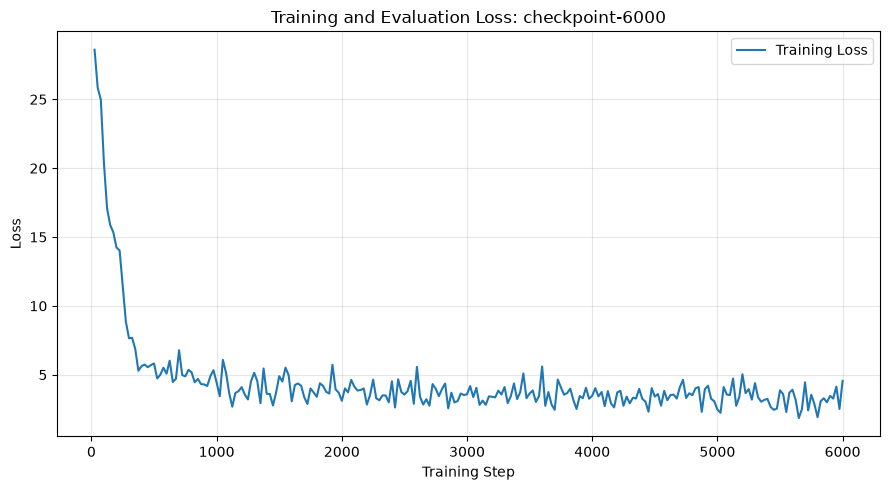

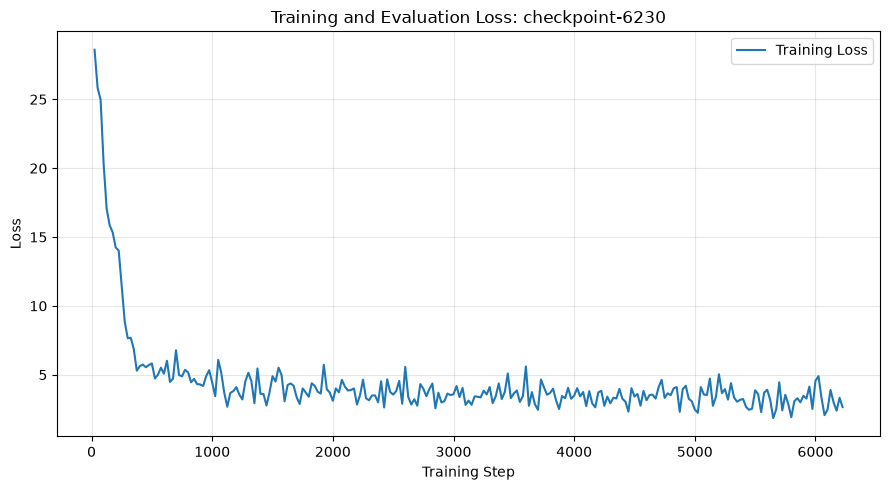


Training log columns: ['epoch', 'grad_norm', 'learning_rate', 'loss', 'step', 'checkpoint']


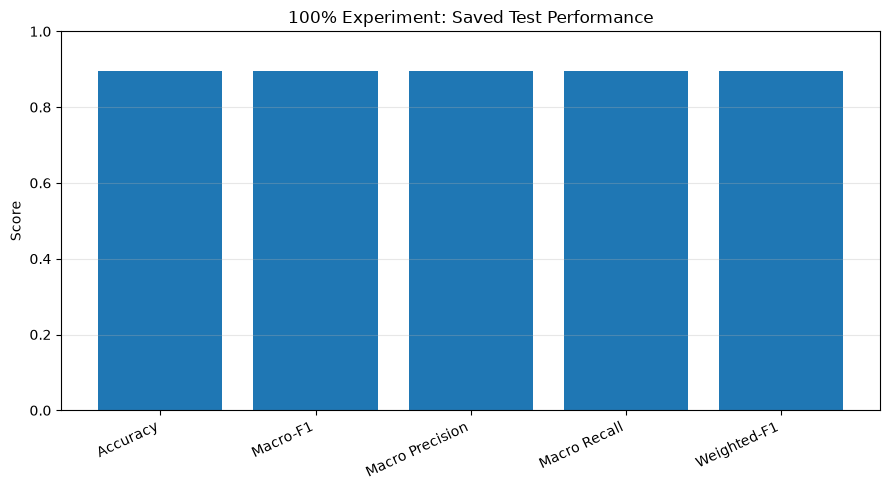

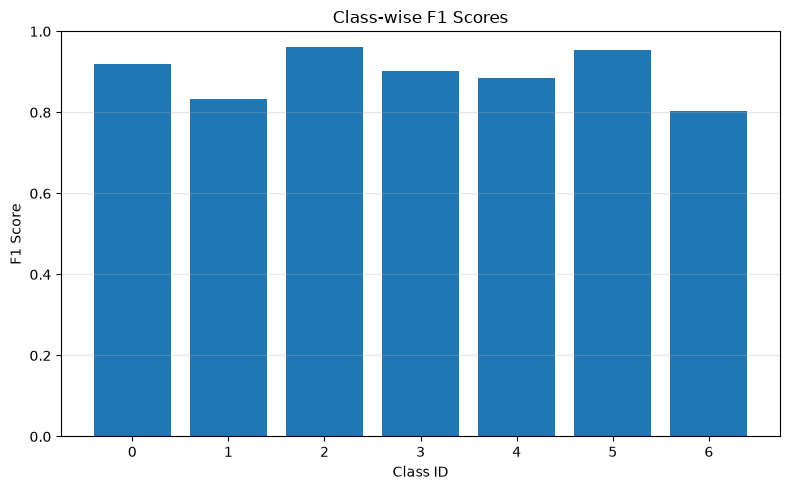


GPU: NVIDIA GeForce RTX 5050
Monitoring GPU during the next 30 seconds...
Average GPU utilization: 0.33%
Peak VRAM usage: 1.21 GB


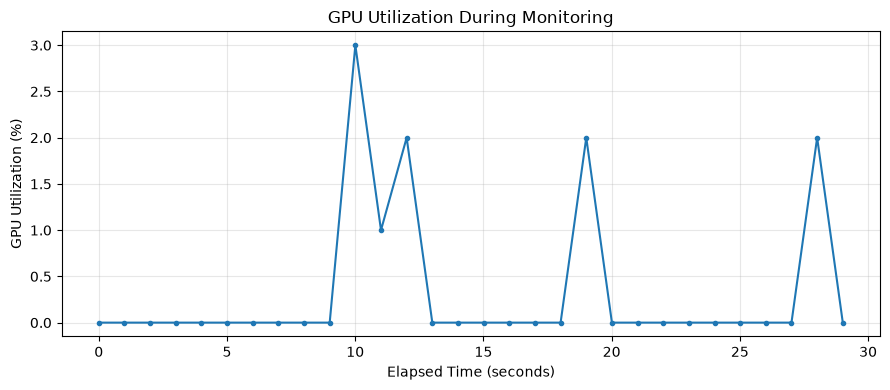

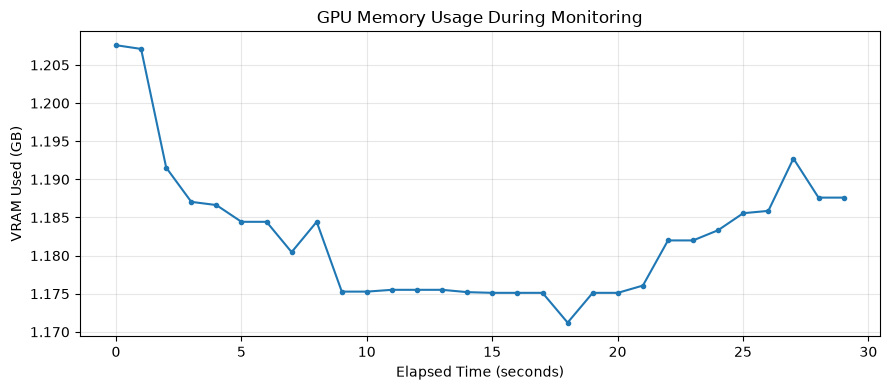

Estimated monitoring energy: 0.000108 kWh
This is not the energy used by the full training run.

EVALUATION ARTIFACTS SAVED
Output folder: C:\Users\Admin\bengali_classification_experiments\100_percent\research_results
class_wise_f1.png
class_wise_metrics.csv
evaluation_summary.json
gpu_memory_usage.png
gpu_usage_log.csv
gpu_utilization.png
loss_curve_checkpoint-6000.png
loss_curve_checkpoint-6230.png
test_performance.png
training_log_history.csv


In [12]:
# ============================================================
# 100% QLoRA Model: Efficiency, Loss, Sustainability and GPU
# This cell does not train or fine-tune the model.
# ============================================================

import json
import time
import platform
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------- Configuration --------------------

BASE = Path(
    r"C:\Users\Admin\bengali_classification_experiments\100_percent"
)
ADAPTER = BASE / "final_adapter"
CHECKPOINTS = BASE / "checkpoints"
RESULTS = BASE / "research_results"

RESULTS.mkdir(parents=True, exist_ok=True)

METRICS_FILE = BASE / "test_metrics.json"
REPORT_FILE = BASE / "test_classification_report.json"

# -------------------- Load Saved Metrics --------------------

metrics = {}
if METRICS_FILE.exists():
    with open(METRICS_FILE, "r", encoding="utf-8") as f:
        metrics = json.load(f)
else:
    print("Warning: Saved test_metrics.json was not found.")

print("=" * 60)
print("SAVED 100% TEST EVALUATION")
print("=" * 60)

for key, value in metrics.items():
    print(f"{key}: {value}")

# -------------------- Check Adapter Files --------------------

print("\n" + "=" * 60)
print("ADAPTER CHECK")
print("=" * 60)

for filename in [
    "adapter_config.json",
    "adapter_model.safetensors",
    "adapter_model.bin",
]:
    file_path = ADAPTER / filename
    print(f"{filename}: {'FOUND' if file_path.exists() else 'NOT FOUND'}")

# -------------------- Load Training Logs --------------------

all_logs = []

for state_file in sorted(
    CHECKPOINTS.glob("checkpoint-*/trainer_state.json")
):
    try:
        with open(state_file, "r", encoding="utf-8") as f:
            state = json.load(f)

        for row in state.get("log_history", []):
            record = row.copy()
            record["checkpoint"] = state_file.parent.name
            all_logs.append(record)

    except Exception as error:
        print("Could not read:", state_file, error)

logs = pd.DataFrame(all_logs)

if not logs.empty:
    logs.to_csv(RESULTS / "training_log_history.csv", index=False)

    # Plot loss curves separately for each checkpoint to avoid
    # mixing logs from different training runs.
    for checkpoint_name, group in logs.groupby("checkpoint"):
        train = (
            group.dropna(subset=["loss"]).sort_values("step")
            if "loss" in group.columns else pd.DataFrame()
        )
        valid = (
            group.dropna(subset=["eval_loss"]).sort_values("step")
            if "eval_loss" in group.columns else pd.DataFrame()
        )

        if train.empty and valid.empty:
            continue

        plt.figure(figsize=(9, 5))

        if not train.empty:
            plt.plot(train["step"], train["loss"], label="Training Loss")

        if not valid.empty:
            plt.plot(
                valid["step"], valid["eval_loss"],
                marker="o", label="Evaluation Loss"
            )

        plt.xlabel("Training Step")
        plt.ylabel("Loss")
        plt.title(f"Training and Evaluation Loss: {checkpoint_name}")
        plt.grid(alpha=0.3)
        plt.legend()
        plt.tight_layout()

        safe_name = checkpoint_name.replace("/", "_")
        plt.savefig(
            RESULTS / f"loss_curve_{safe_name}.png",
            dpi=300, bbox_inches="tight"
        )
        plt.show()
        plt.close()

    print("\nTraining log columns:", logs.columns.tolist())
else:
    print("\nNo saved trainer_state.json logs were found.")

# -------------------- Saved Test Performance --------------------

score_keys = {
    "Accuracy": "test_accuracy",
    "Macro-F1": "test_macro_f1",
    "Macro Precision": "test_macro_precision",
    "Macro Recall": "test_macro_recall",
    "Weighted-F1": "test_weighted_f1",
}

scores = {
    label: metrics[key]
    for label, key in score_keys.items()
    if key in metrics
}

if scores:
    plt.figure(figsize=(9, 5))
    plt.bar(scores.keys(), scores.values())
    plt.ylim(0, 1)
    plt.ylabel("Score")
    plt.title("100% Experiment: Saved Test Performance")
    plt.xticks(rotation=25, ha="right")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        RESULTS / "test_performance.png",
        dpi=300, bbox_inches="tight"
    )
    plt.show()
    plt.close()

# -------------------- Class-wise F1 Scores --------------------

if REPORT_FILE.exists():
    with open(REPORT_FILE, "r", encoding="utf-8") as f:
        report = json.load(f)

    class_rows = []
    for label, values in report.items():
        if (
            isinstance(values, dict)
            and "f1-score" in values
            and str(label).isdigit()
        ):
            class_rows.append({
                "class_id": str(label),
                "precision": values["precision"],
                "recall": values["recall"],
                "f1_score": values["f1-score"],
                "support": values["support"],
            })

    class_df = pd.DataFrame(class_rows)

    if not class_df.empty:
        class_df.to_csv(
            RESULTS / "class_wise_metrics.csv", index=False
        )

        plt.figure(figsize=(8, 5))
        plt.bar(class_df["class_id"], class_df["f1_score"])
        plt.ylim(0, 1)
        plt.xlabel("Class ID")
        plt.ylabel("F1 Score")
        plt.title("Class-wise F1 Scores")
        plt.grid(axis="y", alpha=0.3)
        plt.tight_layout()
        plt.savefig(
            RESULTS / "class_wise_f1.png",
            dpi=300, bbox_inches="tight"
        )
        plt.show()
        plt.close()

# -------------------- GPU Monitoring --------------------

gpu_rows = []
gpu_monitor_available = False

try:
    from pynvml import (
        nvmlInit,
        nvmlShutdown,
        nvmlDeviceGetHandleByIndex,
        nvmlDeviceGetUtilizationRates,
        nvmlDeviceGetMemoryInfo,
        nvmlDeviceGetPowerUsage,
        nvmlDeviceGetName,
    )

    nvmlInit()
    gpu_monitor_available = True
    gpu = nvmlDeviceGetHandleByIndex(0)

    print("\nGPU:", nvmlDeviceGetName(gpu))
    print("Monitoring GPU during the next 30 seconds...")

    duration_seconds = 30
    interval_seconds = 1
    start_time = time.time()

    while time.time() - start_time < duration_seconds:
        utilization = nvmlDeviceGetUtilizationRates(gpu)
        memory = nvmlDeviceGetMemoryInfo(gpu)

        try:
            power_watts = nvmlDeviceGetPowerUsage(gpu) / 1000.0
        except Exception:
            power_watts = np.nan

        gpu_rows.append({
            "elapsed_seconds": time.time() - start_time,
            "gpu_utilization_percent": utilization.gpu,
            "gpu_memory_used_gb": memory.used / (1024 ** 3),
            "gpu_memory_total_gb": memory.total / (1024 ** 3),
            "gpu_power_watts": power_watts,
        })

        time.sleep(interval_seconds)

except Exception as error:
    print("GPU monitoring unavailable:", error)

finally:
    if gpu_monitor_available:
        nvmlShutdown()

gpu_df = pd.DataFrame(gpu_rows)

if not gpu_df.empty:
    gpu_df.to_csv(RESULTS / "gpu_usage_log.csv", index=False)

    avg_gpu = gpu_df["gpu_utilization_percent"].mean()
    peak_vram = gpu_df["gpu_memory_used_gb"].max()

    print(f"Average GPU utilization: {avg_gpu:.2f}%")
    print(f"Peak VRAM usage: {peak_vram:.2f} GB")

    for column, ylabel, title, filename in [
        (
            "gpu_utilization_percent",
            "GPU Utilization (%)",
            "GPU Utilization During Monitoring",
            "gpu_utilization.png",
        ),
        (
            "gpu_memory_used_gb",
            "VRAM Used (GB)",
            "GPU Memory Usage During Monitoring",
            "gpu_memory_usage.png",
        ),
    ]:
        plt.figure(figsize=(9, 4))
        plt.plot(
            gpu_df["elapsed_seconds"],
            gpu_df[column],
            marker="."
        )
        plt.xlabel("Elapsed Time (seconds)")
        plt.ylabel(ylabel)
        plt.title(title)
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.savefig(
            RESULTS / filename, dpi=300, bbox_inches="tight"
        )
        plt.show()
        plt.close()

    # Estimate GPU energy for the monitoring period only.
    power_df = gpu_df.dropna(
        subset=["elapsed_seconds", "gpu_power_watts"]
    ).sort_values("elapsed_seconds")

    if len(power_df) >= 2:
        energy_joules = np.trapezoid(
            power_df["gpu_power_watts"].to_numpy(),
            power_df["elapsed_seconds"].to_numpy()
        )
        energy_kwh = energy_joules / 3_600_000

        print(f"Estimated monitoring energy: {energy_kwh:.6f} kWh")
        print("This is not the energy used by the full training run.")

# -------------------- Efficiency Summary --------------------

summary = {
    "experiment": "100_percent",
    "base_model": "Qwen2.5-3B-Instruct",
    "adapter_path": str(ADAPTER),
    "saved_test_accuracy": metrics.get("test_accuracy"),
    "saved_test_macro_f1": metrics.get("test_macro_f1"),
    "saved_test_loss": metrics.get("test_loss"),
    "saved_test_runtime_seconds": metrics.get("test_runtime"),
    "saved_test_samples_per_second": metrics.get(
        "test_samples_per_second"
    ),
    "saved_test_steps_per_second": metrics.get(
        "test_steps_per_second"
    ),
    "python_version": platform.python_version(),
    "note": (
        "Saved test metrics are historical. GPU statistics in this "
        "report cover only the new monitoring interval."
    ),
}

with open(
    RESULTS / "evaluation_summary.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 60)
print("EVALUATION ARTIFACTS SAVED")
print("=" * 60)
print("Output folder:", RESULTS)

for path in sorted(RESULTS.iterdir()):
    if path.is_file():
        print(path.name)

In [1]:
# Zip all 100% experiment research results into one archive

import zipfile
from pathlib import Path

RESULTS = Path(
    r"C:\Users\Admin\bengali_classification_experiments\100_percent\research_results"
)

ZIP_FILE = Path(
    r"C:\Users\Admin\bengali_classification_experiments\100_percent\100_percent_all_results.zip"
)

if not RESULTS.exists():
    raise FileNotFoundError(f"Results folder not found: {RESULTS}")

with zipfile.ZipFile(ZIP_FILE, "w", zipfile.ZIP_DEFLATED) as zf:
    for file in RESULTS.rglob("*"):
        if file.is_file():
            zf.write(file, file.relative_to(RESULTS.parent))

print("ZIP created successfully!")
print("Location:", ZIP_FILE)
print("Size (MB):", round(ZIP_FILE.stat().st_size / (1024 * 1024), 2))
print("Files included:", len(zf.namelist()) if not zf.fp else "Archive saved")

ZIP created successfully!
Location: C:\Users\Admin\bengali_classification_experiments\100_percent\100_percent_all_results.zip
Size (MB): 0.58
Files included: 10
